# Cell-cell communication

- **Question:** which cell types in the marrow send signals to which others,
  through which ligand–receptor pairs — and which of those calls hold up?
- **Method:** LIANA `rank_aggregate` on the 19 fixed cell-type labels. Each
  possible interaction (ligand–receptor pair × sender × receiver) is scored by
  several methods and merged into two ranks:
  - **magnitude** — how strongly the ligand and receptor are expressed;
  - **specificity** — how restricted that expression is to the two cell types.
  Both ranks are on a 0–1 scale where **small is strong**. An interaction is
  called significant when **both are ≤ 0.05**.
- **Two resources** (ligand–receptor databases): `consensus` (large, merged
  from several databases) and `cellphonedb` (small, curated). Everything else
  is identical, so differences between the two runs come from the database.
- **Settings:** log-normalised expression; a gene must be expressed in ≥ 10%
  of a cell type; cell types under 10 cells are skipped; 1,000 permutations;
  seed 7.
- **Checks on top of the ranking:** agreement between the scoring methods, a
  re-run in each of the eight donor lanes, pathway grouping (KEGG, Reactome),
  and shared signalling patterns (matrix factorisation).
- **Code:** `src/cell_cell_communication/`. Order: `lr_rank`, `lr_methods`,
  `lr_donors`, `lr_pathways`, `lr_patterns`, `cell_communication_report`.
- **This notebook** only reads saved tables and figures. 11 of the 17 stage
  figures are shown; the rest are linked at the end.

In [1]:
from io import BytesIO
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display
from PIL import Image as PILImage

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURES = ROOT / "figures"
RESULTS = ROOT / "results"
MAX_PIXELS = 1600

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 60)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.precision", 3)


def show(figure: str, width: int = 900) -> None:
    """Saved figure, downscaled for display, with a link to the full file."""
    with PILImage.open(FIGURES / figure) as image:
        image.thumbnail((MAX_PIXELS, MAX_PIXELS * 4))
        buffer = BytesIO()
        image.convert("RGB").save(buffer, format="JPEG", quality=85)
    display(Image(data=buffer.getvalue(), format="jpeg", width=width),
            Markdown(f"[Full-resolution figure](../figures/{figure})"))


def table(name: str, **read_options) -> pd.DataFrame:
    """Saved results table, read from the results directory."""
    return pd.read_csv(RESULTS / name, **read_options)

## 1. Ligand–receptor ranking

In [2]:
KEYS = ["source", "target", "ligand_complex", "receptor_complex"]
ranked = {resource: table(f"cell_cell_communication/lr_rank/lr_rank_{resource}_all.csv")
          for resource in ("consensus", "cellphonedb")}
significant = {resource: table(f"cell_cell_communication/lr_rank/lr_rank_{resource}_significant.csv")
               for resource in ranked}


def run_summary(tested: pd.DataFrame, called: pd.DataFrame) -> dict:
    """Counts describing one ranking run."""
    magnitude = int((tested["magnitude_rank"] <= 0.05).sum())
    specificity = int((tested["specificity_rank"] <= 0.05).sum())
    return {
        "ligand–receptor pairs tested": len(tested[KEYS[2:]].drop_duplicates()),
        "interactions tested": len(tested),
        "cell-type pairs tested (of 361)": len(tested[KEYS[:2]].drop_duplicates()),
        "pass magnitude ≤ 0.05": magnitude,
        "pass specificity ≤ 0.05": specificity,
        "pass both (significant)": len(called),
        "expected to pass both if independent": round(magnitude * specificity / len(tested), 1),
        "significant, % of tested": round(100 * len(called) / len(tested), 2),
        "distinct ligand–receptor pairs": len(called[KEYS[2:]].drop_duplicates()),
        "distinct cell-type pairs": len(called[KEYS[:2]].drop_duplicates()),
        "self-signalling": int((called["source"] == called["target"]).sum()),
        "permutation p = 0, % of tested": round(100 * (tested["cellphone_pvals"] == 0).mean(), 1),
    }


pd.DataFrame({resource: run_summary(ranked[resource], significant[resource]) for resource in ranked}, dtype=object)

,consensus,cellphonedb
ligand–receptor pairs tested,465.0,114.0
interactions tested,16438.0,3529.0
cell-type pairs tested (of 361),361.0,354.0
pass magnitude ≤ 0.05,955.0,202.0
pass specificity ≤ 0.05,1279.0,253.0
pass both (significant),195.0,20.0
expected to pass both if independent,74.3,14.5
"significant, % of tested",1.19,0.57
distinct ligand–receptor pairs,34.0,5.0
distinct cell-type pairs,90.0,20.0


- **Consensus calls 195 of 16,438 interactions (1.19%); cellphonedb calls 20 of
  3,529 (0.57%).**
- **The two cut-offs mostly disagree.** In consensus, 955 interactions pass
  magnitude and 1,279 pass specificity, but only 195 pass both — 2.6 times the
  74 expected by chance. In cellphonedb it is 20 against 14.5 (1.4 times),
  close to chance. Loud and cell-type-specific are almost separate questions
  on this data.
- **The permutation p-value is useless here.** It is exactly 0 for 64% of
  everything tested in both runs. With 38,430 cells almost any expressed pair
  beats a shuffled label. It is not used as evidence anywhere in this stage.

In [3]:
overlap = significant["consensus"][KEYS].merge(significant["cellphonedb"][KEYS], how="outer", indicator=True)
pair_sets = {resource: set(frame[KEYS[2:]].itertuples(index=False, name=None))
             for resource, frame in ranked.items()}
display(overlap["_merge"].map({"both": "both", "left_only": "consensus only", "right_only": "cellphonedb only"})
        .value_counts().rename("significant interactions").to_frame().T)
pd.Series({
    "pairs in both resources": len(pair_sets["consensus"] & pair_sets["cellphonedb"]),
    "pairs only in cellphonedb": len(pair_sets["cellphonedb"] - pair_sets["consensus"]),
    "pairs only in consensus": len(pair_sets["consensus"] - pair_sets["cellphonedb"]),
}, name="ligand–receptor pairs tested").to_frame().T

_merge,consensus only,both,cellphonedb only
significant interactions,181,14,6


,pairs in both resources,pairs only in cellphonedb,pairs only in consensus
ligand–receptor pairs tested,91,23,374


- **Only 14 interactions are significant in both resources.** They are the
  stage's core:
  - `APP → CD74` from plasmacytoid DC into 8 receivers (CD74 is the MHC class
    II chaperone, so the receivers are antigen-presenting and B-lineage cells);
  - `TNFSF13B → HLA-DPB1` (BAFF, the B-cell survival factor) into dendritic
    cells from 4 senders;
  - `PF4 → CXCR3` from platelets into T proliferating and plasmacytoid DC.
- **cellphonedb is close to a subset of consensus** (91 of its 114 pairs are
  also in consensus).
- **Two of the six cellphonedb-only hits are real disagreements**:
  `RPS19 → C5AR1` and `CLEC2D → KLRB1` are tested in consensus and not
  significant there. The ranks are relative to their own table — the same
  interaction can be top 1% among 114 pairs and only top 5% among 465.
- **`RPS19 → C5AR1` looks like an artefact**: RPS19 is a ribosomal protein,
  the gene class that contaminated earlier stages.
- **Rule:** significance belongs to the resource, not to the interaction. Say
  which resource every claim comes from.

In [4]:
called = significant["consensus"]
family = called["ligand_complex"].replace({"B2M": "B2M and HLA class I", "HLA-A": "B2M and HLA class I",
                                           "HLA-B": "B2M and HLA class I", "HLA-C": "B2M and HLA class I",
                                           "S100A8": "S100A8/A9/A12", "S100A9": "S100A8/A9/A12",
                                           "S100A12": "S100A8/A9/A12"})
family = family.where(family.isin(["B2M and HLA class I", "S100A8/A9/A12"]), "other")
display(pd.DataFrame({"interactions": family.value_counts(),
                      "ligands": called.groupby(family)["ligand_complex"].nunique()}))
display(called.groupby(KEYS[2:]).size().nlargest(11).rename("interactions").to_frame().T)
pd.concat([called["source"].value_counts().head(7).rename_axis("sender").reset_index(name="sent"),
           called["target"].value_counts().head(7).rename_axis("receiver").reset_index(name="received")], axis=1)

,interactions,ligands
ligand_complex,,
B2M and HLA class I,80,4
S100A8/A9/A12,76,3
other,39,13


ligand_complex     B2M HLA-B S100A8       S100A9   B2M  APP S100A8       \
receptor_complex KLRD1 KLRD1   CD69 ITGB2  ITGB2 KLRC1 CD74   CD36 CD68   
interactions        15    14     14    12     12    11    9      9    9   

ligand_complex   S100A9       
receptor_complex   CD36 CD68  
interactions          9    9

,sender,sent,receiver,received
0,Monocyte classical,55,NK,47
1,Granulocyte precursor,32,Monocyte non-classical,26
2,NK,14,T proliferating,25
3,CD8 T cytotoxic,13,Dendritic cell,19
4,Plasmacytoid DC,12,Plasmacytoid DC,13
5,CD8 T memory,11,Monocyte classical,13
6,T proliferating,10,CD8 T memory,10


- **Two ligand families carry 80% of the consensus result**: B2M and HLA class
  I (80 rows, 4 ligands) and S100A8/A9/A12 (76 rows, 3 ligands). The other 13
  ligands give 39 rows.
- **The class I block is true but says nothing new.** `B2M → KLRD1`,
  `HLA-B → KLRD1` and `B2M → KLRC1` always go into NK, because KLRD1 (CD94)
  and KLRC1 (NKG2A) are NK-only receptors — but B2M and class I are made by
  almost every cell. "Every cell shows class I to NK cells" is textbook, not a
  finding about this marrow.
- **The S100 block is the monocyte marker list again.** S100A8/A9/A12 are the
  top markers of classical monocytes (core pipeline) and among the strongest
  monocyte fate drivers (trajectory). The receptors (ITGB2, CD36, CD68, CD69)
  are correct, but the block cannot add evidence beyond the markers.
- **Sender and receiver totals follow from these blocks.** Monocyte classical
  and Granulocyte precursor send 87 of 195 rows (45%); NK receives 47 (24%).
  These counts measure how many loud, well-annotated ligands a cell type owns,
  not how much it signals.

In [5]:
hspc = pd.DataFrame({
    resource: {"sent": int((frame["source"] == "HSPC").sum()), "received": int((frame["target"] == "HSPC").sum())}
    for resource, frame in significant.items()
})
display(hspc.rename_axis("HSPC"))
levels = ["lr_means", "expr_prod", "lrscore", "magnitude_rank", "specificity_rank"]
rest = called[~called["ligand_complex"].isin(["CDH1", "ERFE"])]
display(pd.concat([called.loc[called["ligand_complex"].isin(["CDH1", "ERFE"]), KEYS + levels].set_index(KEYS),
                   rest[levels].median().rename("median of the other 193").to_frame().T]).round(4))
called.nsmallest(5, "specificity_rank")[KEYS + ["scaled_weight", "specificity_rank"]]

,consensus,cellphonedb
HSPC,,
sent,0,0
received,1,1


,lr_means,expr_prod,lrscore,magnitude_rank,specificity_rank
"(Erythroid early, Erythroid early, CDH1, LRP5)",0.095,0.007,0.518,0.022,0.023
"(Erythroid early, Monocyte classical, ERFE, LRP1)",0.131,0.009,0.547,0.047,0.038
median of the other 193,2.531,3.743,0.962,0.006,0.010


,source,target,ligand_complex,receptor_complex,scaled_weight,specificity_rank
122,Platelet,T proliferating,PF4,CXCR3,8.472,4.974e-08
152,Platelet,NK,CLEC1B,KLRB1,6.634,1.822e-07
182,Platelet,Plasmacytoid DC,PF4,CXCR3,8.109,3.552e-07
17,Monocyte classical,Erythroid early,S100A9,CD36,2.319,4.625e-05
19,Monocyte classical,Erythroid early,S100A8,CD36,2.313,4.804e-05


- **HSPC is invisible**: it sends nothing in either resource and receives one
  interaction (`APP → CD74` from plasmacytoid DC). Its identity genes (CD34,
  SPINK2, AVP, CRHBP) are stemness markers that belong to no ligand–receptor
  database — the same reason it was blank in the pathway stage.
- **Two significant interactions are barely expressed**: `CDH1 → LRP5` and
  `ERFE → LRP1` from Erythroid early. Their expression products (0.007,
  0.009) are about 430–550 times below the median of the rest (3.74). They
  pass because the magnitude rank is a *rank*: a gene in just over 10% of one
  cell type and nowhere else can still rank high. **Rule: read `lr_means` and
  `expr_prod` before believing a rank.**
- **The three most specific interactions are all sent by platelets**:
  `PF4 → CXCR3` into T proliferating and into plasmacytoid DC, and
  `CLEC1B → KLRB1` into NK, with specificity ranks 10–1,000 times better than
  the next row. PF4 and CLEC1B are made only by megakaryocytes and platelets,
  so the sender is unambiguous. `PF4 → CXCR3` also holds the best specificity
  rank in cellphonedb.
- **Caveat: size.** Platelet is 103 cells, T proliferating 47, plasmacytoid DC
  330 — the cleanest result rests on three small groups.

In [6]:
pd.DataFrame({
    "interactions": significant["cellphonedb"].groupby(KEYS[2:]).size(),
    "senders": significant["cellphonedb"].groupby(KEYS[2:])["source"].unique().map(", ".join),
}).sort_values("interactions", ascending=False)

,,interactions,senders
ligand_complex,receptor_complex,,
APP,CD74,9,"Plasmacytoid DC, Platelet"
TNFSF13B,HLA-DPB1,6,"Monocyte classical, Granulocyte precursor, Dendritic cell, Monocyte non-clas..."
PF4,CXCR3,2,Platelet
RPS19,C5AR1,2,"B naive, CD4 T naive"
CLEC2D,KLRB1,1,T proliferating


- **cellphonedb: 20 interactions from 5 ligand–receptor pairs.** Plasmacytoid
  DC sends 8 of the 20, all `APP → CD74`; the 9th `APP → CD74` row is
  Platelet → B naive.
- **`TNFSF13B → HLA-DPB1` (BAFF) from myeloid senders into dendritic cells and
  B naive** is one of the few results in the stage that is neither a
  housekeeping ligand nor a marker gene.

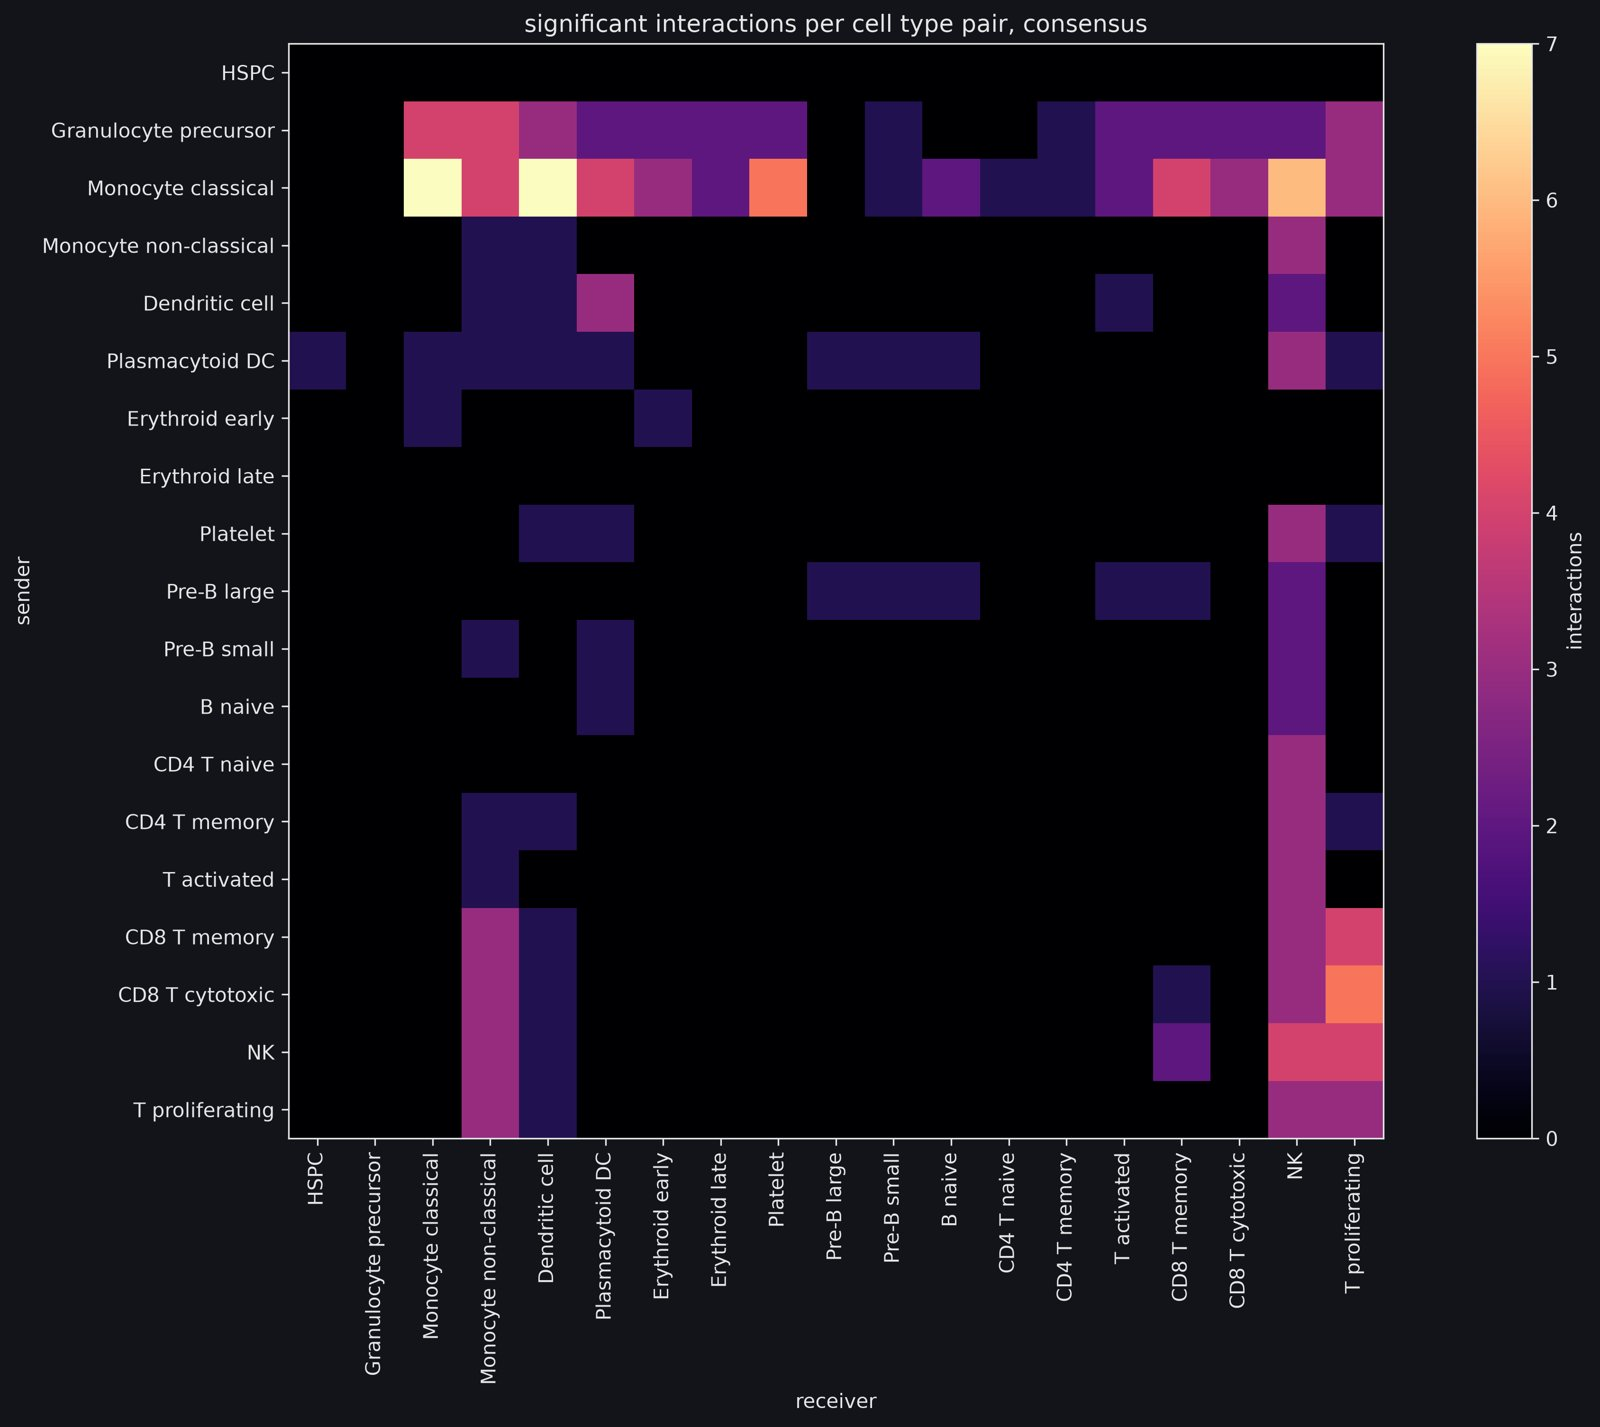

[Full-resolution figure](../figures/cell_cell_communication/lr_rank/lr_rank_heatmap_consensus.png)

In [7]:
show("cell_cell_communication/lr_rank/lr_rank_heatmap_consensus.png", width=750)

- **Significant interactions per sender × receiver, consensus**; colour scale
  0–7, shared with the cellphonedb panel (linked at the end).
- **Two bright rows and one bright column**: Monocyte classical (7 into itself
  and into dendritic cells, 6 into NK, 5 into platelets), Granulocyte
  precursor below it, and the NK column down most of the matrix.
- **Empty**: the HSPC row (one cell in its column), the Erythroid late row and
  the Granulocyte precursor column.
- Read alone, the figure says "monocytes talk to everything and everything
  talks to NK" — both halves are the two ligand blocks above.
- The cellphonedb panel has 20 non-zero cells, each equal to 1.
  *Corrected 15 Oct 2026: the stage report said 19.*

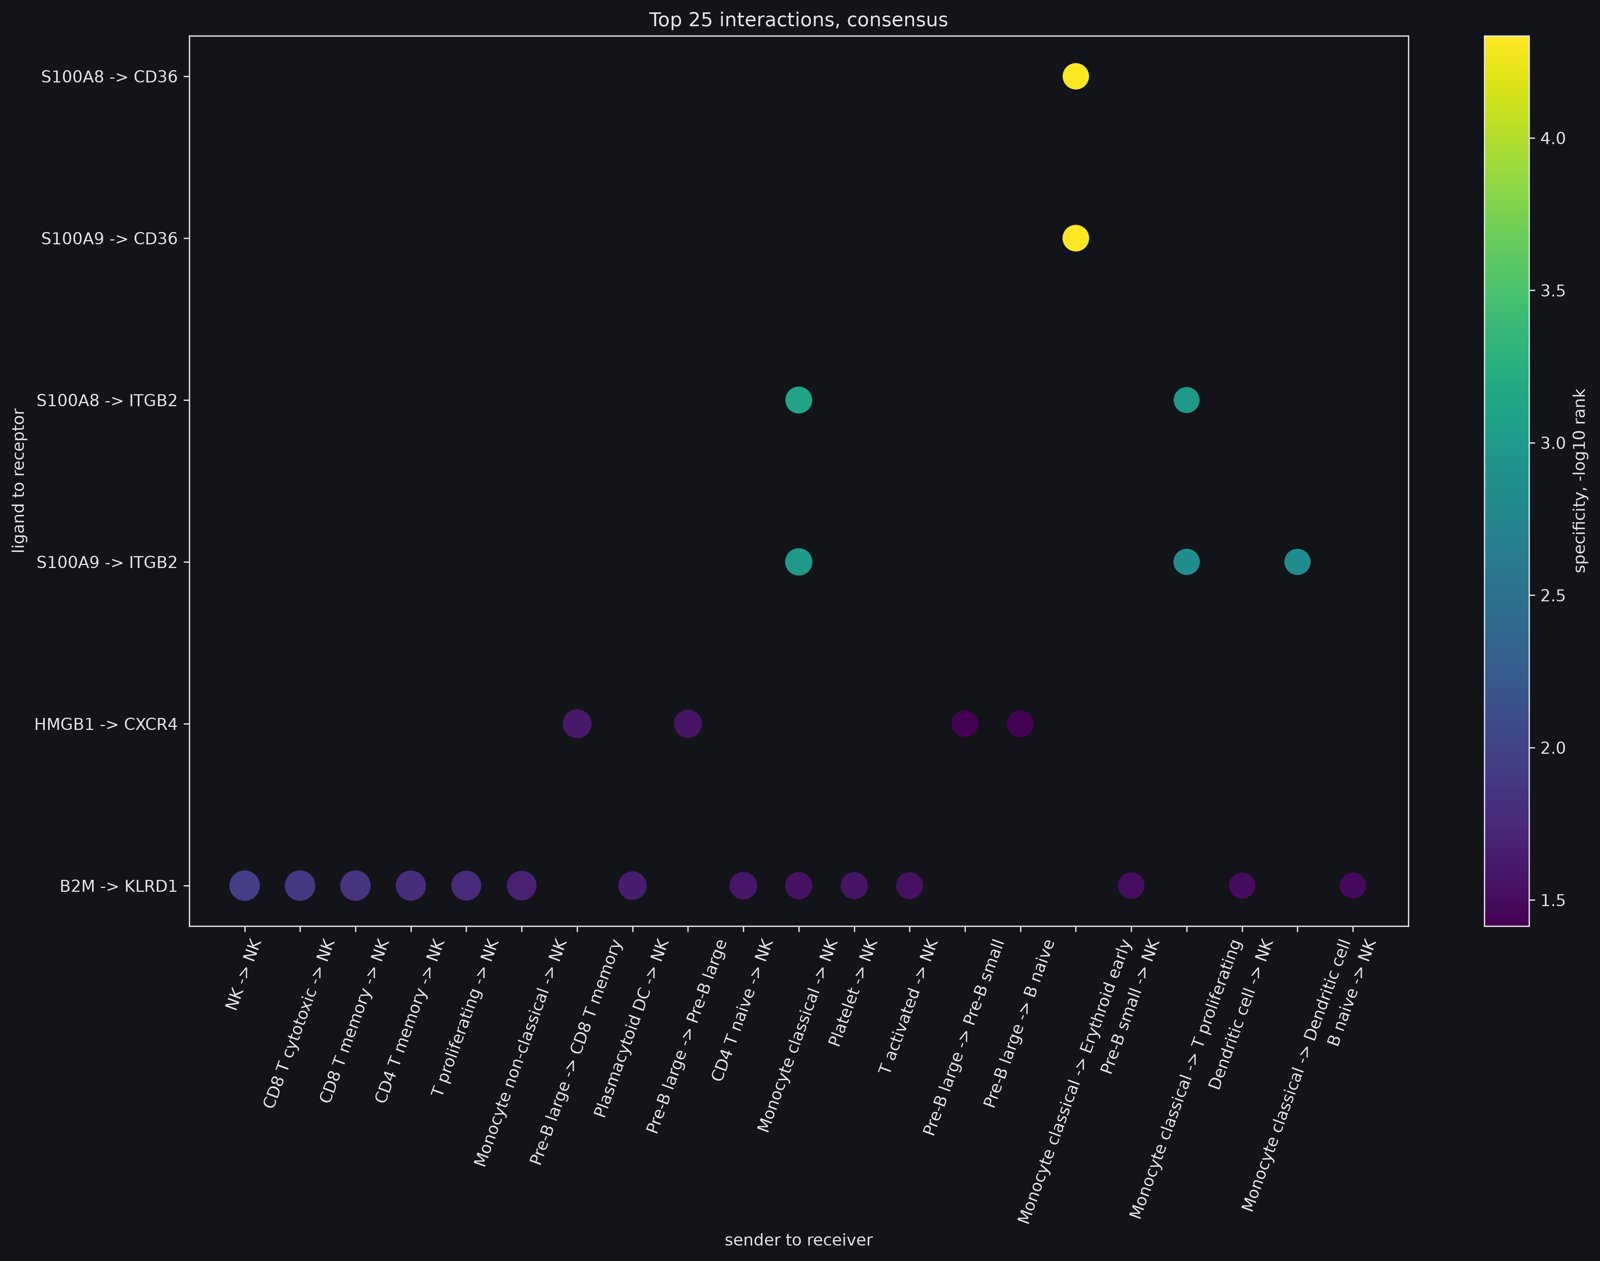

[Full-resolution figure](../figures/cell_cell_communication/lr_rank/lr_rank_dotplot_consensus.png)

In [8]:
show("cell_cell_communication/lr_rank/lr_rank_dotplot_consensus.png")

- **Top 25 interactions by magnitude**; dot size = magnitude, colour =
  specificity (brighter = more specific).
- **Only six ligand–receptor pairs** fill the top 25. `B2M → KLRD1` alone takes
  14 of them, from 14 senders, all into NK, and is uniformly dark (least
  specific). *Corrected 15 Oct 2026: the stage report said 13 senders.*
- **The two brightest dots** are `S100A8/S100A9 → CD36` from Monocyte classical
  into Erythroid early — the most specific rows are not the most frequent.

## 2. Do the scoring methods agree?

In [9]:
correlation = table("cell_cell_communication/lr_methods/lr_methods_correlation.csv")
correlation[correlation["resource"] == "consensus"].drop(columns="resource").set_index("method").round(2)

,CellPhoneDB magnitude,NATMI magnitude,SingleCellSignalR magnitude,Merged magnitude,CellPhoneDB specificity,NATMI specificity,Connectome specificity,log2FC specificity,Merged specificity
method,,,,,,,,,
CellPhoneDB magnitude,1.00,0.95,0.95,0.57,0.27,0.23,0.36,0.38,0.31
NATMI magnitude,0.95,1.00,1.00,0.55,0.25,0.24,0.34,0.37,0.31
SingleCellSignalR magnitude,0.95,1.00,1.00,0.55,0.25,0.24,0.34,0.37,0.31
Merged magnitude,0.57,0.55,0.55,1.00,0.15,0.15,0.23,0.23,0.19
CellPhoneDB specificity,0.27,0.25,0.25,0.15,1.00,0.65,0.77,0.78,0.75
NATMI specificity,0.23,0.24,0.24,0.15,0.65,1.00,0.87,0.77,0.85
Connectome specificity,0.36,0.34,0.34,0.23,0.77,0.87,1.00,0.87,0.89
log2FC specificity,0.38,0.37,0.37,0.23,0.78,0.77,0.87,1.00,0.88
Merged specificity,0.31,0.31,0.31,0.19,0.75,0.85,0.89,0.88,1.00


In [10]:
table("cell_cell_communication/lr_methods/lr_methods_agreement.csv").set_index(["resource", "method"]).round(2)

spearman_magnitude  \
resource    method                                            
consensus   CellPhoneDB magnitude                      0.57   
            NATMI magnitude                            0.55   
            SingleCellSignalR magnitude                0.55   
            CellPhoneDB specificity                    0.15   
            NATMI specificity                          0.15   
            Connectome specificity                     0.23   
            log2FC specificity                         0.23   
cellphonedb CellPhoneDB magnitude                      0.57   
            NATMI magnitude                            0.55   
            SingleCellSignalR magnitude                0.55   
            CellPhoneDB specificity                    0.21   
            NATMI specificity                          0.12   
            Connectome specificity                     0.29   
            log2FC specificity                         0.23   

                                         shared_top100_magnitude  \
resource    method                                                 
consensus   CellPhoneDB magnitude                             61   
            NATMI magnitude                                   81   
            SingleCellSignalR magnitude                       81   
            CellPhoneDB specificity                           83   
            NATMI specificity                                  0   
            Connectome specificity                             0   
            log2FC specificity                                21   
cellphonedb CellPhoneDB magnitude                             74   
            NATMI magnitude                                   66   
            SingleCellSignalR magnitude                       66   
            CellPhoneDB specificity                           77   
            NATMI specificity                                  2   
            Connectome specificity                             8   
            log2FC specificity                                18   

                                         spearman_specificity  \
resource    method                                              
consensus   CellPhoneDB magnitude                        0.31   
            NATMI magnitude                              0.31   
            SingleCellSignalR magnitude                  0.31   
            CellPhoneDB specificity                      0.75   
            NATMI specificity                            0.85   
            Connectome specificity                       0.89   
            log2FC specificity                           0.88   
cellphonedb CellPhoneDB magnitude                        0.32   
            NATMI magnitude                              0.34   
            SingleCellSignalR magnitude                  0.34   
            CellPhoneDB specificity                      0.74   
            NATMI specificity                            0.84   
            Connectome specificity                       0.88   
            log2FC specificity                           0.88   

                                         shared_top100_specificity  
resource    method                                                  
consensus   CellPhoneDB magnitude                                7  
            NATMI magnitude                                      4  
            SingleCellSignalR magnitude                          4  
            CellPhoneDB specificity                              4  
            NATMI specificity                                   36  
            Connectome specificity                              48  
            log2FC specificity                                  26  
cellphonedb CellPhoneDB magnitude                                6  
            NATMI magnitude                                      5  
            SingleCellSignalR magnitude                          5  
            CellPhoneDB specificity                              5  
     

- **Spearman correlation of each method's score**, all flipped so higher =
  stronger; 7 method scores plus the 2 merged ranks. Nothing is recomputed —
  every score was already in the ranking table.
- **Seven methods are really two measurements.** The three magnitude scores
  agree at 0.95–1.00; the four specificity scores at 0.65–0.87. Between the
  two blocks: 0.23–0.38.
- **NATMI and SingleCellSignalR magnitude are the same ranking** (Spearman
  0.99999999998) — one score is a monotone transform of the other. "Seven
  methods merged" should not be written in any summary.
- **The merged specificity rank follows its inputs** (0.75–0.89). **The merged
  magnitude rank does not** (0.55–0.57), although its three inputs agree
  almost perfectly. The aggregate saturates: 3,648 rows (22%) share one value.
  Read merged magnitude as a coarse ordering.
- **Merged magnitude vs merged specificity: 0.19** — the two halves of the
  significance test are close to independent, as section 1 found.
- **No correlation is negative** (smallest 0.15 consensus, 0.12 cellphonedb):
  the methods never point opposite ways; they differ only in strength.
- **Top-100 overlap:** NATMI and Connectome specificity share **0** of their top
  100 with merged magnitude in consensus — at the top, loud and specific are
  disjoint. The 83 for CellPhoneDB specificity is not agreement: its p-value is
  tied at 0 for 64% of rows, so its "top 100" is just the first 100 rows of a
  file sorted by magnitude.
- **Connectome specificity is the single method closest to the merged
  specificity** (0.89 / 0.88; top-100 overlap 48 / 55).
- **cellphonedb vs consensus:** the cross-block correlations are higher in
  cellphonedb in 14 of 20 cells; all four NATMI-specificity cells are lower.
  *Corrected 15 Oct 2026: the stage report said every cross-block cell was
  higher and gave the range as 0.21–0.43; it is 0.12–0.43.*

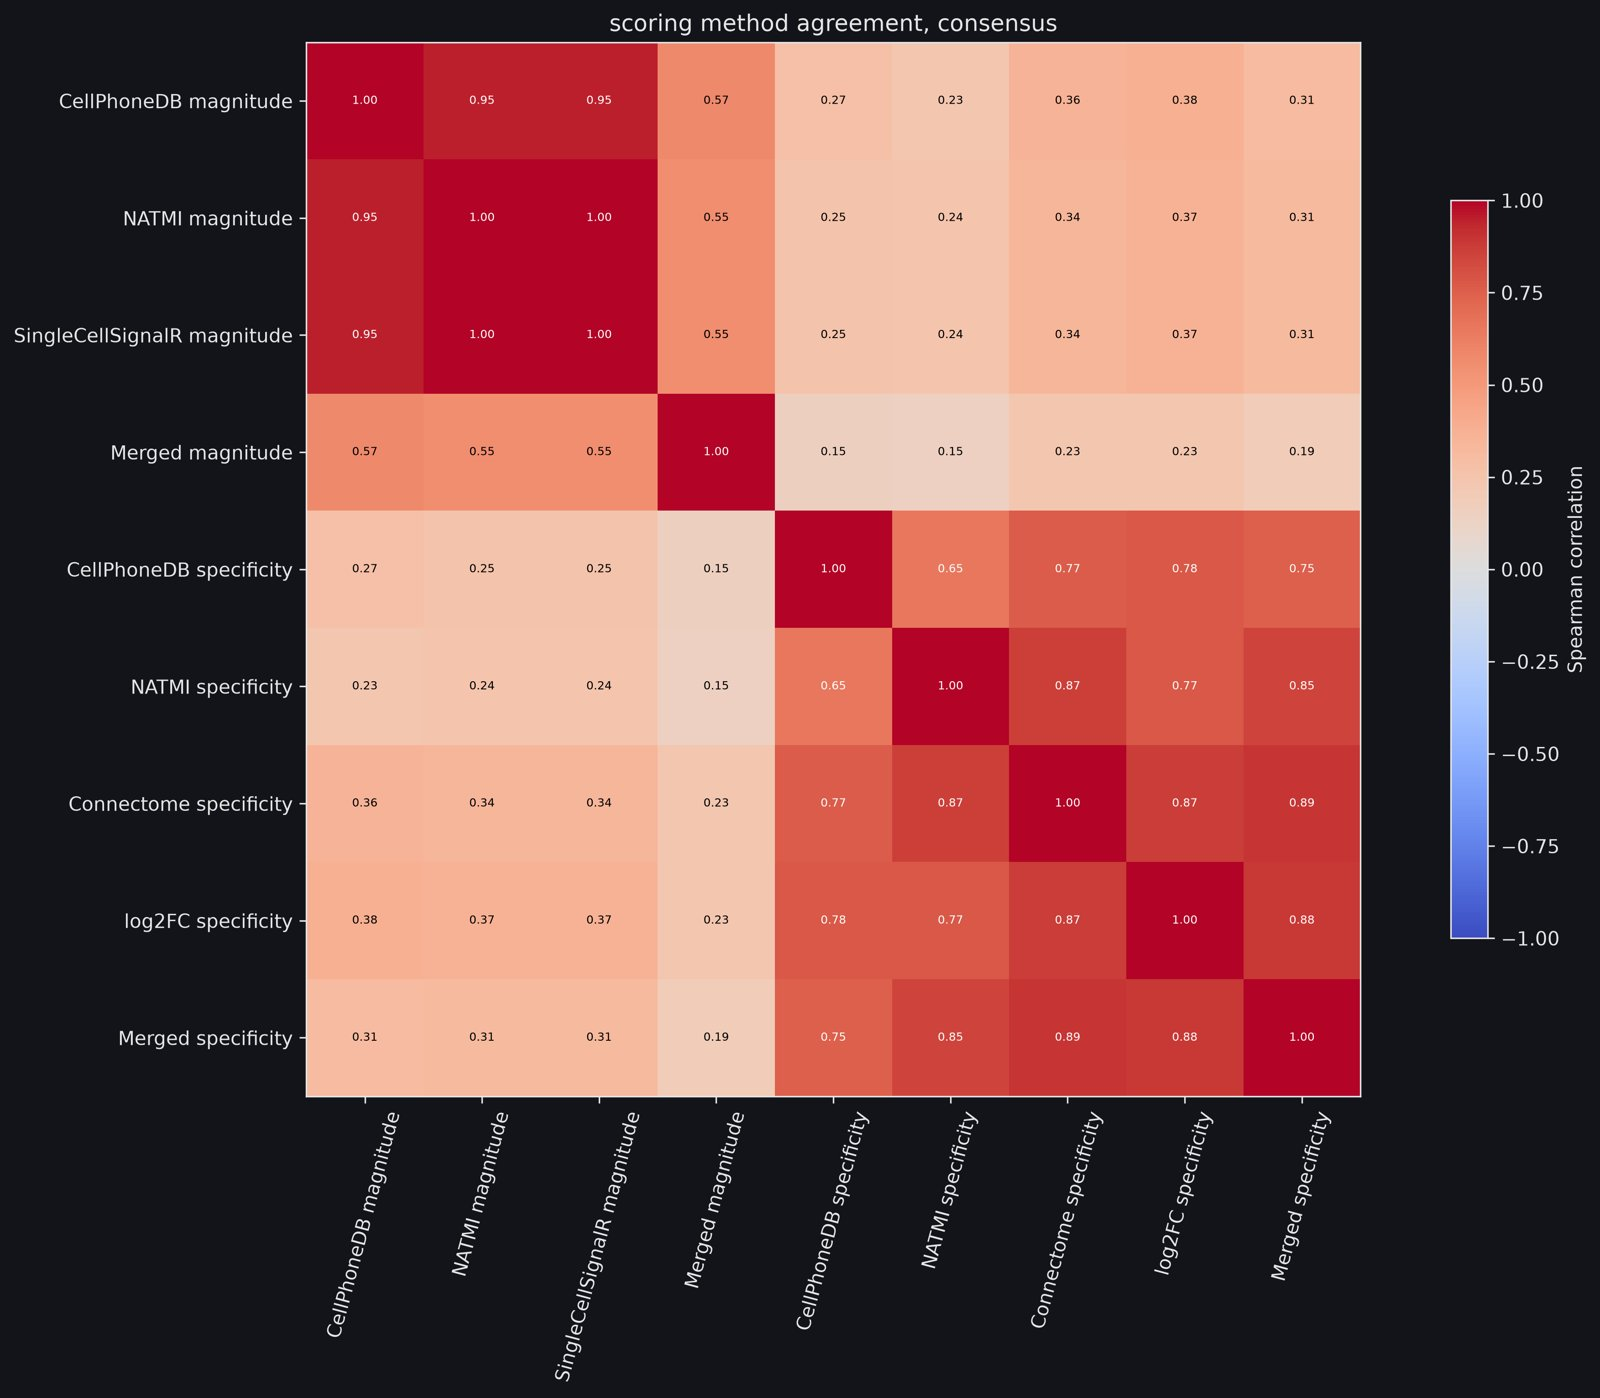

[Full-resolution figure](../figures/cell_cell_communication/lr_methods/lr_methods_agreement_consensus.png)

In [11]:
show("cell_cell_communication/lr_methods/lr_methods_agreement_consensus.png", width=700)

- **Fixed scale −1 to 1**; the blue half is unused because nothing is negative.
- **Two squares on the diagonal**: magnitude (top left) and specificity (bottom
  right).
- **The `Merged magnitude` row is the palest** (0.15–0.57) — it sits apart
  even from its own three inputs. The `Merged specificity` row is warm across
  all four specificity methods.

## 3. Does it reproduce donor by donor?

In [12]:
coverage = table("cell_cell_communication/lr_donors/lr_donors_coverage.csv")
cells_per_lane = coverage.pivot(index="cell_type", columns="donor", values="cells").fillna(0).astype(int)
cells_per_lane["largest lane share"] = cells_per_lane.max(axis=1) / cells_per_lane.sum(axis=1)
cells_per_lane["lanes testable"] = coverage[coverage["testable"]].groupby("cell_type").size()
cells_per_lane.sort_values("largest lane share", ascending=False).round(3)

donor,MantonBM1,MantonBM2,MantonBM3,MantonBM4,MantonBM5,MantonBM6,MantonBM7,MantonBM8,largest lane share,lanes testable
cell_type,,,,,,,,,,
T activated,0,1,532,0,17,2,1,30,0.913,3
T proliferating,4,0,5,22,2,4,0,10,0.468,2
Monocyte non-classical,32,118,401,138,81,18,77,36,0.445,8
CD8 T cytotoxic,83,484,816,120,139,181,283,201,0.354,8
Erythroid early,121,54,57,172,407,151,73,116,0.354,8
NK,121,666,80,471,54,270,403,88,0.309,8
B naive,648,1318,313,491,726,457,591,474,0.263,8
Pre-B small,267,140,15,139,30,89,265,80,0.260,8
Pre-B large,85,33,5,67,7,20,87,30,0.260,6


- **The same ranking was re-run in each of the eight donor lanes** (4,542 to
  5,073 cells each). A label is skipped in a lane where it has under 10 cells.
- **T activated is one donor: 532 of its 583 cells (91.3%) are in MantonBM3.**
  It is testable in 3 lanes of 8. Earlier stages already called it the weakest
  label (no distinctive marker, only CD69 and BTG1 — immediate-early genes a
  differently handled sample would show). It is most likely a MantonBM3
  handling effect, not a cell type. **Any result involving T activated is a
  MantonBM3 result.** The labels stay fixed by rule.
- **Every label is unevenly spread over donors**: largest single-lane share has
  a median of 0.25 against 0.125 for an even split. NK runs 54–666 cells per
  lane, Monocyte non-classical 18–401, HSPC 26–184. This does not contradict
  the weak batch effect from the benchmark: that measured whether cells mix,
  this measures how many of each type each donor gave.
- **15 of 19 labels are testable in all 8 lanes**; T proliferating (2),
  T activated (3), Platelet (5) and Pre-B large (6) drop out somewhere.

In [13]:
lanes = pd.concat([table(f"cell_cell_communication/lr_donors/lr_donors_MantonBM{lane}.csv") for lane in range(1, 9)])
display(lanes.groupby(["resource", "donor"]).size().unstack("donor")
        .assign(**{"pooled run": [len(significant["cellphonedb"]), len(significant["consensus"])]}))
reproducible = table("cell_cell_communication/lr_donors/lr_donors_reproducible.csv")
pd.crosstab([reproducible["resource"], reproducible["significant_full"]], reproducible["donor_significant"],
            rownames=["resource", "significant in pooled run"], colnames=["lanes calling it"])

donor,MantonBM1,MantonBM2,MantonBM3,MantonBM4,MantonBM5,MantonBM6,MantonBM7,MantonBM8,pooled run
resource,,,,,,,,,
cellphonedb,58,54,21,48,32,56,49,38,20
consensus,442,395,232,443,309,423,337,409,195


lanes calling it                       0    1    2   3   4   5   6   7   8
resource    significant in pooled run                                     
cellphonedb False                      0   47   21   9   6   6  11   1   0
            True                       1    1    3   0   1   1   2   3   8
consensus   False                      0  307  139  51  33  46  55  31  31
            True                       3    2   39  15   7  12  11  32  74

- **Each lane calls more than the pooled run** (consensus 232–443 per lane
  against 195 pooled; cellphonedb 21–58 against 20) on a fifth of the cells.
  This is not more signal: fewer cells give noisier group means, and each lane
  ranks against a different set of labels. **Counts are not comparable across
  lanes or with the pooled run** — only *which* interactions recur carries
  over.
- **Of the 195 pooled consensus interactions, 74 (38%) are called in all 8
  lanes, 117 (60%) in 6 or more, 44 (23%) in 2 or fewer.** cellphonedb: 8 of
  20 in all 8 lanes, 13 in 6 or more, 5 in 2 or fewer.
- **The split is two-humped** (a peak at 8 lanes, a lump at 2), so "6 or more
  lanes = reproducible, 2 or fewer = not" separates two real groups.
- **307 consensus interactions are called in exactly one lane and nowhere
  else** — the noise floor of a one-donor analysis of this size.
- **31 interactions are called in all 8 lanes but not in the pooled run**, and
  31 more in 7 lanes (next table).

In [14]:
pooled = reproducible[(reproducible["resource"] == "consensus") & reproducible["significant_full"]]
display(pooled[pooled["donor_significant"] == 0])
missed = (reproducible[(reproducible["resource"] == "consensus") & ~reproducible["significant_full"]
                       & (reproducible["donor_significant"] == 8)].merge(ranked["consensus"], on=KEYS))
display(pd.Series({
    "interactions": len(missed),
    "pass magnitude in pooled run": int((missed["magnitude_rank"] <= 0.05).sum()),
    "pass specificity in pooled run": int((missed["specificity_rank"] <= 0.05).sum()),
    "specificity rank, min": round(missed["specificity_rank"].min(), 4),
    "specificity rank, max": round(missed["specificity_rank"].max(), 4),
}, name="called in all 8 lanes, missed when pooled", dtype=object).to_frame().T)
missed["target"].value_counts().rename("receivers").to_frame().T

,resource,source,target,ligand_complex,receptor_complex,donor_significant,significant_full
885,consensus,Pre-B large,T activated,HMGB1,CXCR4,0,True
886,consensus,Erythroid early,Monocyte classical,ERFE,LRP1,0,True
887,consensus,Platelet,T proliferating,PF4,CXCR3,0,True


,interactions,pass magnitude in pooled run,pass specificity in pooled run,"specificity rank, min","specificity rank, max"
"called in all 8 lanes, missed when pooled",31,31,0,0.054,0.059


target,CD8 T memory,CD8 T cytotoxic,CD4 T memory,Granulocyte precursor,Pre-B small
receivers,12,9,7,2,1


- **Three pooled interactions reproduce in no lane, for three different
  reasons:**
  - `PF4 → CXCR3`, Platelet → T proliferating — **untestable**: Platelet clears
    the 10-cell floor in BM1, 2, 3, 6, 7 and T proliferating in BM4, 8; no lane
    has both. The flagship specific result cannot be checked per donor. Its
    twin into plasmacytoid DC is testable and does reproduce.
  - `ERFE → LRP1` — **refuted**: both labels are testable in all 8 lanes and
    none calls it. With its near-zero expression, it is an artefact.
  - `HMGB1 → CXCR4`, Pre-B large → T activated — **thin evidence**: jointly
    testable only in MantonBM8, which did not call it; the receiver is the
    one-donor label.
- **The pooled run misses 31 interactions that every lane finds.** All 31 pass
  magnitude and all fail specificity, by a hair (rank 0.054–0.059 against the
  0.05 cut-off). 28 of 31 go into mature T subsets (CD8 T memory 12, CD8 T
  cytotoxic 9, CD4 T memory 7), mostly class I → CD8A and LGALS1 → PTPRC.
- **Why:** pooled, these receivers compete for "specific" against CD4 T naive
  — 10,765 cells, 28% of the data. Per lane its share varies (16–41%) and the
  same interactions clear. **A very large cell type creates false negatives
  for its smaller relatives.**
- *Corrected 15 Oct 2026: the stage report gave the CD4 T naive lane share as
  18–44% and the upper specificity rank as 0.0590; the saved tables give
  16–41% and 0.0585.*

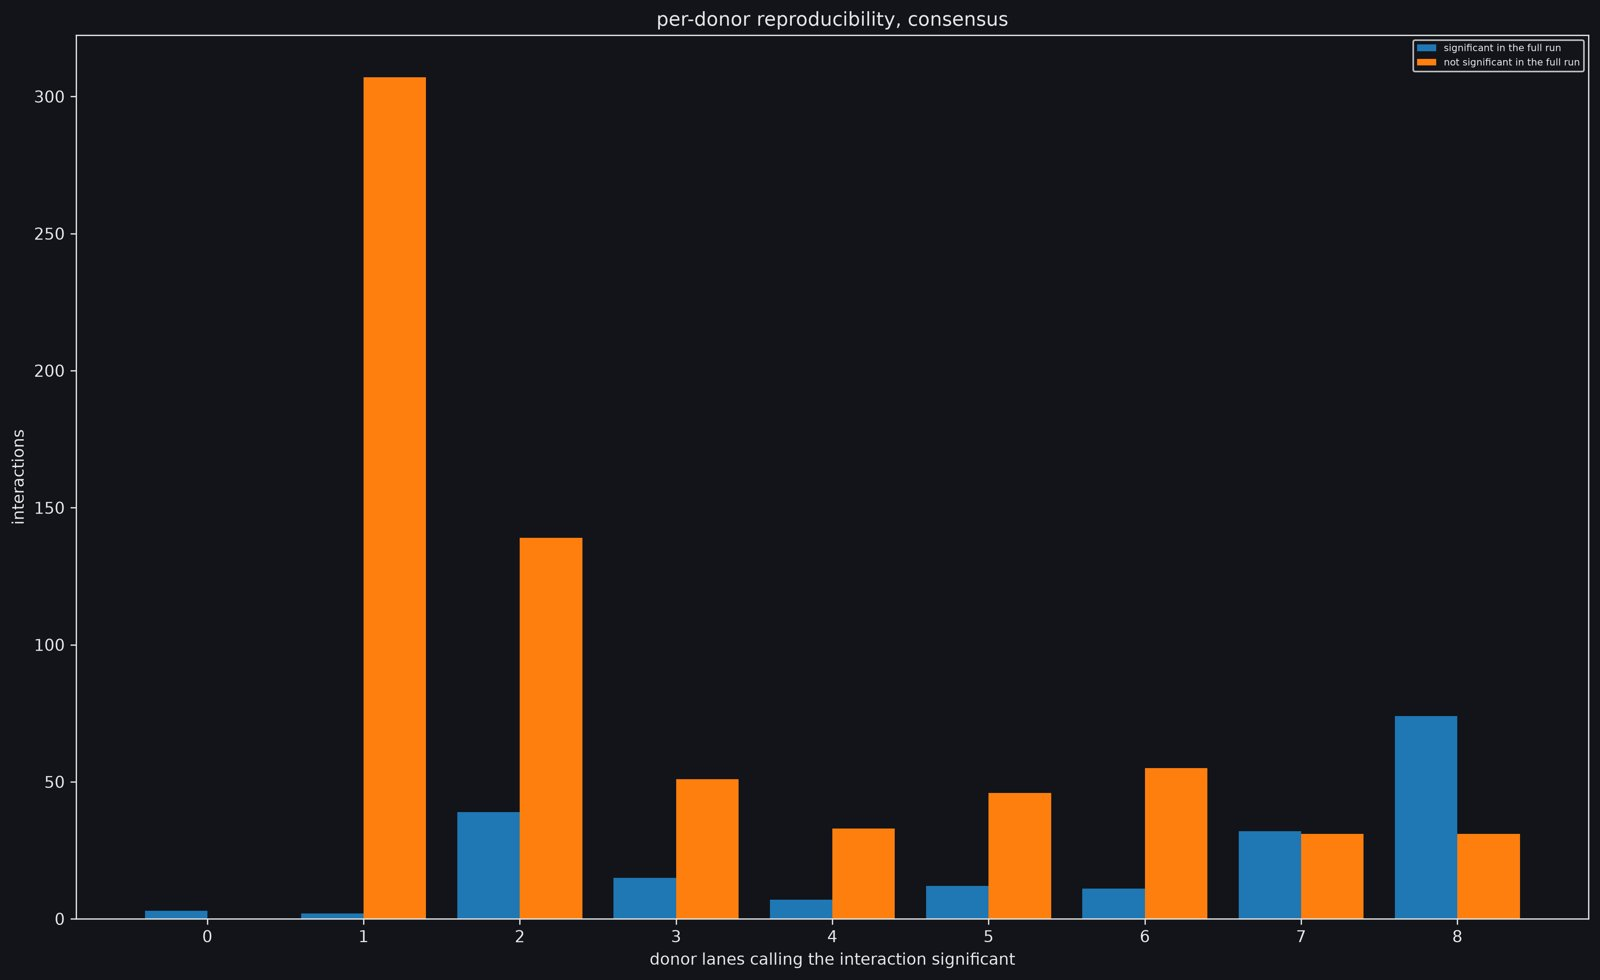

[Full-resolution figure](../figures/cell_cell_communication/lr_donors/lr_donors_reproducibility_consensus.png)

In [15]:
show("cell_cell_communication/lr_donors/lr_donors_reproducibility_consensus.png")

- **Interactions by number of lanes calling them**; blue = significant in the
  pooled run, orange = not.
- **The orange bar at 1 lane (307)** is the noise floor; **the blue bars rise
  to 74 at 8 lanes** — the pooled result confirmed.
- **At 7 and 8 lanes orange matches blue (31 each)**: the only place the two
  colours are level is where the pooled run's false negatives sit.
- The cellphonedb version (linked) has no orange bar at 8 lanes: with 114
  pairs nothing is pushed just over the line.

## 4. Pathways: what the significant interactions add up to

In [16]:
pathway_rows = table("cell_cell_communication/lr_pathways/lr_pathways_consensus.csv")
mapped = pathway_rows[KEYS].drop_duplicates()
unmapped = called.merge(mapped, on=KEYS, how="left", indicator=True).query("_merge == 'left_only'")
display(pd.Series({"significant": len(called), "in at least one pathway": len(mapped),
                   "in no pathway": len(unmapped)}, name="consensus").to_frame().T)
unmapped.groupby(KEYS[2:]).size().sort_values(ascending=False).rename("interactions in no pathway").to_frame().T

,significant,in at least one pathway,in no pathway
consensus,195,158,37


ligand_complex,S100A8,APP,HMGB1,LGALS1,ERFE,CXCL8,CLEC1B,LGALS1
receptor_complex,CD69,CD74,CXCR4,CD69,LRP1,CD79A,KLRB1,ITGB1
interactions in no pathway,14,9,5,5,1,1,1,1


- **Rule used:** a KEGG or Reactome term is assigned only when its gene set
  holds **both** the ligand and the receptor. GO was left out on purpose
  (5,406 process terms, not pathways).
- **158 of 195 (81%) map to a pathway; 37 do not — and they are the wrong 37.**
  All 9 `APP → CD74` rows (significant in both resources) and all 14
  `S100A8 → CD69` rows (the second most frequent pair) have no pathway.
- **The pathway view is blindest where the evidence is strongest.** Being in a
  curated pathway and being reproducible are unrelated.
- cellphonedb: 11 of 20 map; the 9 that do not are all `APP → CD74`.

In [17]:
pathways = table("cell_cell_communication/lr_pathways/lr_pathways_summary.csv")
found = pathways[(pathways["resource"] == "consensus") & (pathways["n_significant"] > 0)]
display(pd.Series({"terms tested": int((pathways["resource"] == "consensus").sum()),
                   "terms with a significant interaction": len(found),
                   "of these, at or below the base rate": int((found["fold_enrichment"] <= 1).sum())},
                  name="consensus").to_frame().T)
found.sort_values("fold_enrichment", ascending=False)[
    ["library", "pathway", "n_tested", "n_significant", "fold_enrichment", "ligands"]].round(2)

,terms tested,terms with a significant interaction,"of these, at or below the base rate"
consensus,419,45,17


,library,pathway,n_tested,n_significant,fold_enrichment,ligands
0,KEGG_2021_Human,Gastric cancer,1,1,84.30,CDH1
1,Reactome_Pathways_2024,DAP12 Interactions,225,30,11.24,B2M;HLA-B
2,Reactome_Pathways_2024,Antigen processing-Cross Presentation,158,18,9.60,S100A8;S100A9
3,Reactome_Pathways_2024,Class I MHC Mediated Antigen Processing & Presentation,158,18,9.60,S100A8;S100A9
4,Reactome_Pathways_2024,ER-Phagosome Pathway,158,18,9.60,S100A8;S100A9
5,Reactome_Pathways_2024,MyD88 Deficiency (TLR2 4),158,18,9.60,S100A8;S100A9
6,Reactome_Pathways_2024,Regulation of TLR by Endogenous Ligand,158,18,9.60,S100A8;S100A9
7,Reactome_Pathways_2024,Diseases Associated With the TLR Signaling Cascade,162,18,9.37,S100A8;S100A9
8,Reactome_Pathways_2024,Diseases of Immune System,162,18,9.37,S100A8;S100A9
9,Reactome_Pathways_2024,IRAK4 Deficiency (TLR2 4),162,18,9.37,S100A8;S100A9


- **Fold enrichment** = share of a term's tested interactions that are
  significant ÷ the overall rate (1.19% for consensus). Below 1 means the term
  holds *fewer* hits than chance.
- **45 terms are really about 15 sets of interactions.** Terms with identical
  hit lists repeat Reactome's parent–child levels: 8 terms carry the same 18
  `S100A8/A9 → CD36` rows, 11 carry the same 6 class II rows. Counting
  "pathways found" inflates the result about threefold.
- **17 of the 45 terms sit at or below the base rate** — the whole class II /
  TCR block (0.61–0.98), `Cell adhesion molecules` (23 hits, 0.84),
  `Signaling by Interleukins` (0.24). Sorting by hit count would have shown
  these as findings. *Corrected 15 Oct 2026: the stage report said 11.*
- **The top row is an artefact**: `Gastric cancer` at 84-fold is one of one
  interaction — the unexpressed `CDH1 → LRP5`. Read fold and count together.
- **Names can say the opposite of the content**: `Class I MHC Mediated Antigen
  Processing & Presentation` is entirely `S100A8/A9 → CD36` (no MHC gene);
  `Signaling by Interleukins` is `S100A12 → CD36` (no interleukin). Open the
  pairs before repeating a term name.
- **What survives:** `Immunoregulatory Interactions Between a Lymphoid and a
  non-Lymphoid Cell` (79 hits, 2.7-fold — class I into NK and CD8 receptors,
  correctly named); the PF4/CCL5 chemokine terms (2.4–5.5-fold for five of
  eight terms, and the only pathway result both resources reach); TNFSF13B
  (BAFF) under `Rheumatoid arthritis` (2.4-fold, 7.7 in cellphonedb).

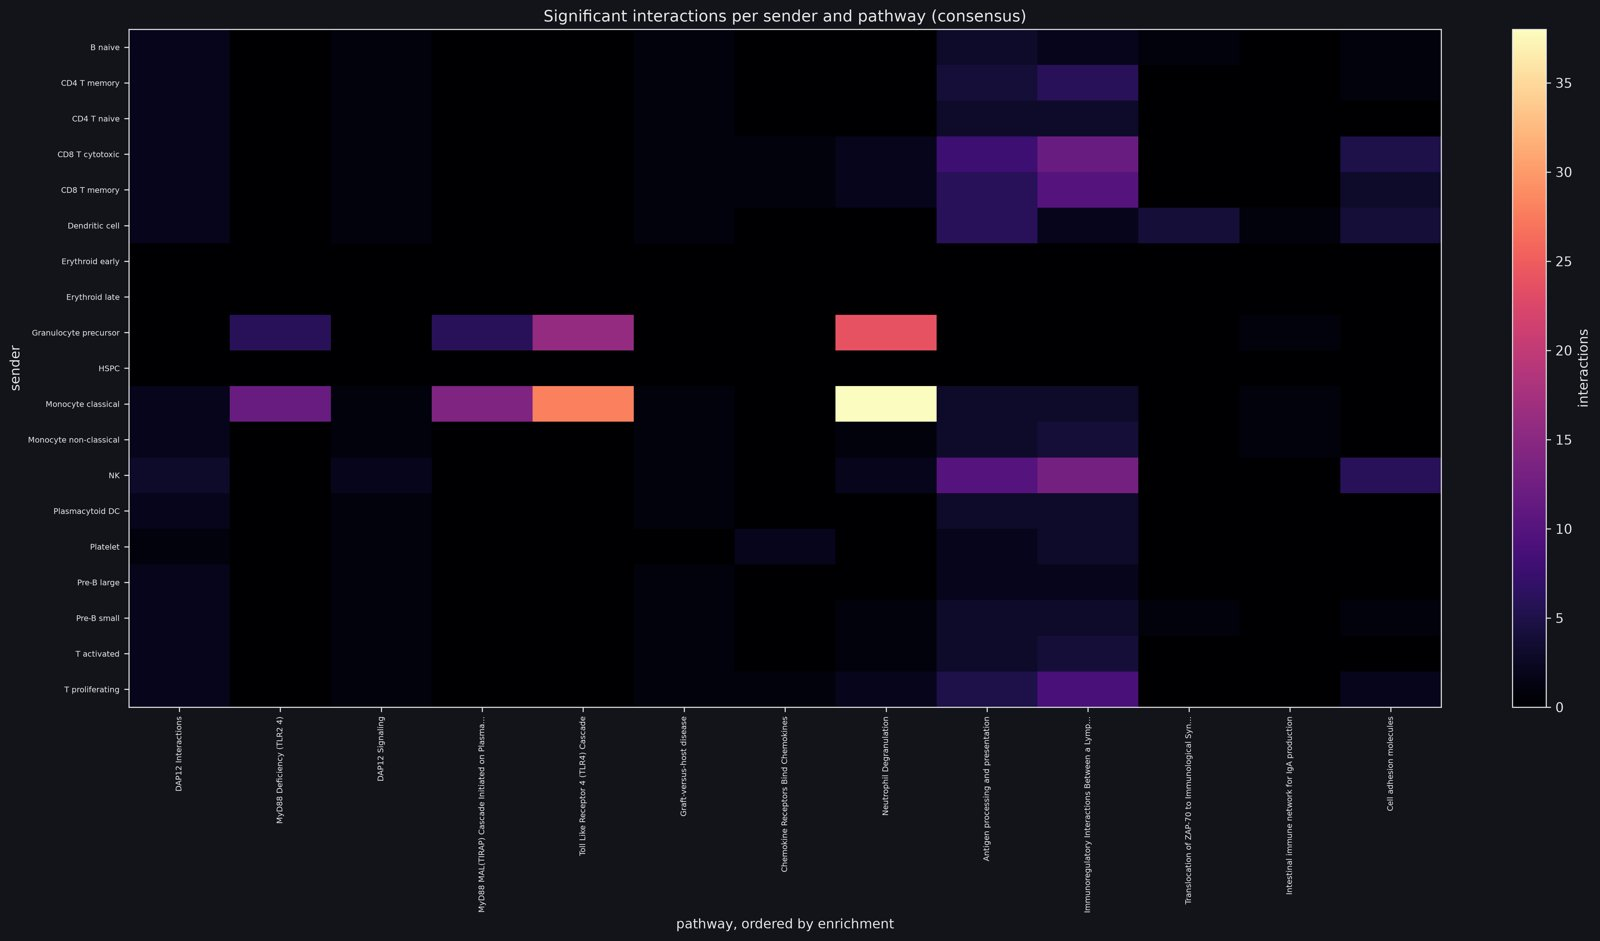

[Full-resolution figure](../figures/cell_cell_communication/lr_pathways/lr_pathways_heatmap.png)

In [18]:
show("cell_cell_communication/lr_pathways/lr_pathways_heatmap.png")

- **Senders × pathways**, consensus; columns ordered left to right by fold
  enrichment; only terms with ≥ 3 hits, identical terms collapsed (13
  columns).
- **The brightest cells are mid-axis, not on the left**: Monocyte classical ×
  `Neutrophil Degranulation` (38) and × `TLR4 Cascade` (28), at 3.1 and
  7.5-fold. The most enriched columns (DAP12, 11.2-fold) are dim. Size and
  enrichment point opposite ways.
- **The last three columns are below the base rate** — depletion, not a
  finding.
- **Empty rows: HSPC, Erythroid early and Erythroid late.** *Corrected 15 Oct
  2026: the stage report put one Erythroid early cell (`Gastric cancer`) in this
  figure; that term has one hit and is below the 3-hit floor.*
- **Two senders give 53% of all pathway rows** (Monocyte classical 261,
  Granulocyte precursor 130, of 742).
- Some column names describe their content badly (`MyD88 Deficiency (TLR2 4)` is
  `S100A8/A9 → CD36`) — the collapse keeps the smallest set's name.

## 5. Shared signalling patterns

In [19]:
errors = table("cell_cell_communication/lr_patterns/lr_patterns_rank.csv")
errors.pivot(index="direction", columns="n_patterns", values="reconstruction_error").round(3)

n_patterns,2,3,4,5,6
direction,,,,,
incoming,6.122,5.433,4.883,4.255,3.686
outgoing,5.641,4.624,4.144,3.837,3.319


- **Method:** non-negative matrix factorisation of a cell type × interaction
  count matrix (the 195 consensus hits), each interaction scaled to its own
  maximum; 4 patterns; seed 7. Done twice: by sender (outgoing) and by
  receiver (incoming).
- **The fit error falls smoothly from 2 to 6 patterns with no elbow** in either
  direction. Four is a readability choice; the data supports no particular
  number. Read everything below as "at four patterns".

In [20]:
usage = table("cell_cell_communication/lr_patterns/lr_patterns_usage.csv")
loadings = table("cell_cell_communication/lr_patterns/lr_patterns_loadings.csv")
usage["label"] = usage["cell_type"] + " " + usage["usage"].round(2).astype(str)
loadings["label"] = loadings["interaction"] + " " + loadings["loading"].round(3).astype(str)
loadings["square"] = loadings["loading"] ** 2
spread = loadings.groupby(["direction", "pattern"]).agg(total=("loading", "sum"), squares=("square", "sum"))
pd.DataFrame({
    "cell types with usage ≥ 0.5": usage[usage["usage"] >= 0.5].sort_values("usage", ascending=False)
    .groupby(["direction", "pattern"])["label"].agg(", ".join),
    "top 5 interactions (loading)": loadings.sort_values("loading", ascending=False)
    .groupby(["direction", "pattern"]).head(5).groupby(["direction", "pattern"])["label"].agg(", ".join),
    "effective size": (spread["total"] ** 2 / spread["squares"]).round(1),
}).sort_index(ascending=[False, True])

cell types with usage ≥ 0.5  \
direction pattern                                                                                      
outgoing  pattern 1  B naive 1.0, Pre-B large 1.0, Pre-B small 0.95, Dendritic cell 0.81, T activ...   
          pattern 2                               Granulocyte precursor 1.0, Monocyte classical 0.71   
          pattern 3             NK 1.0, CD8 T cytotoxic 1.0, CD8 T memory 0.96, T proliferating 0.77   
          pattern 4                              Erythroid early 1.0, Platelet 1.0, CD4 T memory 0.6   
incoming  pattern 1                      Monocyte non-classical 0.8, Plasmacytoid DC 0.76, HSPC 0.53   
          pattern 2                               NK 1.0, CD8 T cytotoxic 0.99, T proliferating 0.73   
          pattern 3  T activated 1.0, Pre-B small 0.92, B naive 0.89, CD4 T naive 0.81, CD4 T mem...   
          pattern 4   Erythroid late 1.0, Erythroid early 1.0, Monocyte classical 0.58, Platelet 0.5   

                                                                        top 5 interactions (loading)  \
direction pattern                                                                                      
outgoing  pattern 1  HLA-B -> KLRD1 0.277, B2M -> KLRD1 0.252, B2M -> KLRC1 0.099, HLA-B -> LILRB...   
          pattern 2  LGALS1 -> CD69 0.096, TNFSF13B -> HLA-DPB1 0.093, S100A9 -> CD68 0.087, S100...   
          pattern 3  HLA-A -> LILRB2 0.096, B2M -> CD1C 0.093, HLA-B -> LILRB2 0.092, B2M -> KLRC...   
          pattern 4  B2M -> KLRC1 0.246, B2M -> KLRD1 0.18, B2M -> CD1C 0.179, PF4 -> CXCR3 0.14,...   
incoming  pattern 1  APP -> CD74 0.162, S100A8 -> CD68 0.148, S100A9 -> CD68 0.148, HLA-DRA -> CD...   
          pattern 2  S100A9 -> ITGB2 0.155, S100A8 -> ITGB2 0.155, S100A8 -> CD69 0.082, HLA-C ->...   
          pattern 3  HMGB1 -> CXCR4 0.315, S100A8 -> CD69 0.258, APP -> CD74 0.181, LGALS1 -> CD6...   
          pattern 4  S100A8 -> CD36 0.261, S100A9 -> CD36 0.261, S100A12 -> CD36 0.17, CDH1 -> LR...   

                     effective size  
direction pattern                    
outgoing  pattern 1             5.8  
          pattern 2            13.0  
          pattern 3            12.0  
          pattern 4             6.0  
incoming  pattern 1            10.5  
          pattern 2            12.0  
          pattern 3             4.6  
          pattern 4             5.5

- **Usage** = how much of a cell type's signalling the pattern explains (each
  row rescaled to sum to 1). **Effective size** = how many interactions the
  pattern behaves as if it has; a value close to the member count means a flat
  set, not a ranking.
- **Outgoing — two patterns are real:**
  - **pattern 2, the myeloid alarmin program**: Granulocyte precursor and
    Monocyte classical only; S100A8/A9 into CD68, ITGB2, CD36, CD69, plus
    LGALS1 and TNFSF13B.
  - **pattern 3, the cytotoxic program**: CD8 T cytotoxic, NK, CD8 T memory,
    T proliferating; class I into LILRB2, CD8A, KLRC1, CD1C.
  - Both are flat (effective size 13 and 12): sets that travel together.
- **Outgoing patterns 1 and 4 are mixtures**: 1 joins class I into NK
  receptors with class II into CD4; 4 joins the platelet ligands (PF4, CLEC1B)
  with B2M into NK receptors.
- **Incoming pattern 4 is the stage's one new result**: S100A8/A9/A12 into
  **CD36** on both erythroid stages (CD36 is a real erythroid receptor). It is
  the only place Erythroid late appears in the whole stage.
- **Incoming pattern 3 crosses compartments** (T activated, Pre-B, B naive,
  naive and memory T), but its top loading is `HMGB1 → CXCR4` — the
  interaction the donor check could barely test, into the one-donor label.
- **The cytotoxic group appears in both directions** (outgoing 3, incoming 2):
  two separate factorisations, one group — the most stable structure here.
- **No pattern separates developing from finished cells.**
- S100A8 and S100A9 have identical loadings everywhere: one variable counted
  twice.

In [21]:
usage.drop_duplicates(["direction", "cell_type"]).pivot(
    index="cell_type", columns="direction", values="total_usage").sort_values("outgoing", ascending=False)

direction,incoming,outgoing
cell_type,,
Monocyte classical,1.532,1.689e+00
Platelet,0.709,1.252e+00
CD4 T memory,0.331,8.671e-01
Monocyte non-classical,1.058,7.324e-01
Granulocyte precursor,NaN,7.224e-01
Plasmacytoid DC,1.027,7.098e-01
CD4 T naive,0.166,6.742e-01
T proliferating,1.243,6.534e-01
T activated,0.763,6.394e-01


- **`total_usage` is the fit before the row rescaling** — it shows whether a
  "usage 1.00" is real.
- **Erythroid early reads 1.00 in outgoing pattern 4, exactly like Platelet,
  but its fit is 2.3 × 10⁻³⁸ against Platelet's 1.25.** Its only outgoing
  interactions are the two unexpressed artefacts (`CDH1 → LRP5`,
  `ERFE → LRP1`); the factorisation cannot place it, and rescaling hides that.
- **HSPC (incoming) is split 0.53 / 0.47 over two patterns at a fit of 0.33** —
  what a method does with no information (HSPC receives one interaction). Not
  a finding.
- **CD4 T naive has the weakest incoming fit (0.17)** although it is 28% of
  the data — the large-label problem from section 3, seen from the receiving
  side.
- **Monocyte classical is the best-fitted cell type in both directions** (1.69
  out, 1.53 in): the S100 programs again.

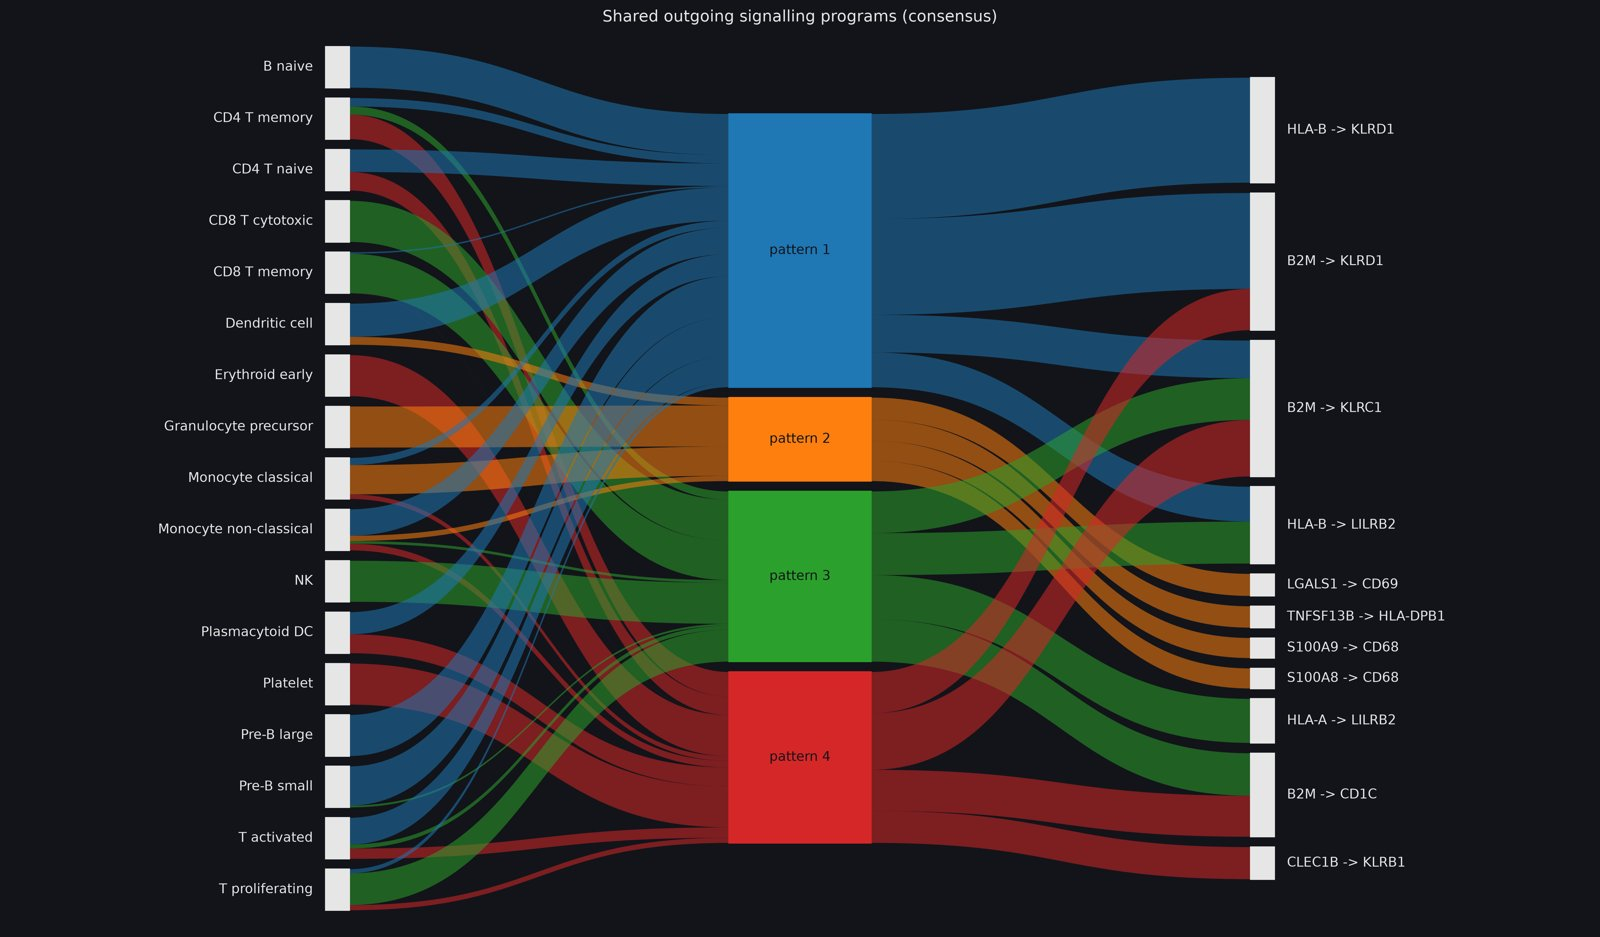

[Full-resolution figure](../figures/cell_cell_communication/lr_patterns/lr_patterns_programs.png)

In [22]:
show("cell_cell_communication/lr_patterns/lr_patterns_programs.png")

- **Outgoing patterns as a flow**: 17 senders (left) → 4 patterns (middle) →
  the 4 top interactions of each (right; 11 distinct).
- **Pattern 2 (orange)** comes only from Granulocyte precursor and Monocyte
  classical and ends in S100, LGALS1 and TNFSF13B; **pattern 3 (green)** comes
  from the cytotoxic labels into LILRB2 and class I; **pattern 1 (blue)** is
  the widest, from most of the B lineage and dendritic cells.
- **Caution:** Erythroid early is drawn with a full-height ribbon into pattern 4,
  identical to Platelet — but its fit is effectively zero (table above). The
  figure cannot show fit strength.

## 6. The whole picture: who signals to whom

In [23]:
summary = table("cell_cell_communication/cell_communication_report/cell_communication_report_summary.csv")
summary["net (received − sent)"] = summary["received"] - summary["sent"]
display(summary.groupby("compartment")[["sent_to_developing", "sent_to_finished"]].sum()
        .rename_axis("sender compartment"))
summary.set_index("cell_type").sort_values("net (received − sent)", ascending=False)

,sent_to_developing,sent_to_finished
sender compartment,,
developing,8,37
finished,9,141


,compartment,sent,received,self,sent_to_developing,sent_to_finished,net (received − sent)
cell_type,,,,,,,
NK,finished,14,47,4,0,14,33
Monocyte non-classical,finished,5,26,1,0,5,21
T proliferating,finished,10,25,3,0,10,15
Dendritic cell,finished,8,19,1,0,8,11
Erythroid early,developing,2,6,1,1,1,4
Erythroid late,developing,0,4,0,0,0,4
T activated,finished,4,6,0,0,4,2
HSPC,developing,0,1,0,0,0,1
B naive,finished,3,4,0,0,3,1


- **Compartments**: developing = HSPC, Granulocyte precursor, Erythroid early
  and late, Pre-B large and small (6 labels); finished = the other 13.
- **Only 17 of 195 interactions go into the developing compartment (8.7%)**,
  against 62 expected if receivers were equal — 3.6 times fewer.
- **Only 5 cell types send anything into it**: Monocyte classical (6),
  Granulocyte precursor (5), Plasmacytoid DC (3), Pre-B large (2), Erythroid
  early (1, the `CDH1 → LRP5` artefact). **The other 14 send nothing there.**
  *Corrected 15 Oct 2026: the stage report said 13.*
- **The traffic in uses two channels**: S100A8/A9/A12 → CD36 into the two
  erythroid stages (9) and `APP → CD74` from plasmacytoid DC (3); plus
  S100A8 → CD69 into Pre-B small (2) and HMGB1 → CXCR4 inside the B lineage (2).
- **This is partly about receptors**: developing cells express few annotated
  receptors above the 10% threshold. Granulocyte precursor sends 32 and
  receives 0 — the only label with nothing incoming.
- **Net balance runs from −42 (Monocyte classical) to +33 (NK)** — the two
  ligand blocks again, not signalling activity. 19 interactions are
  self-signalling, over 8 cell types (Monocyte classical 7, NK 4,
  T proliferating 3).

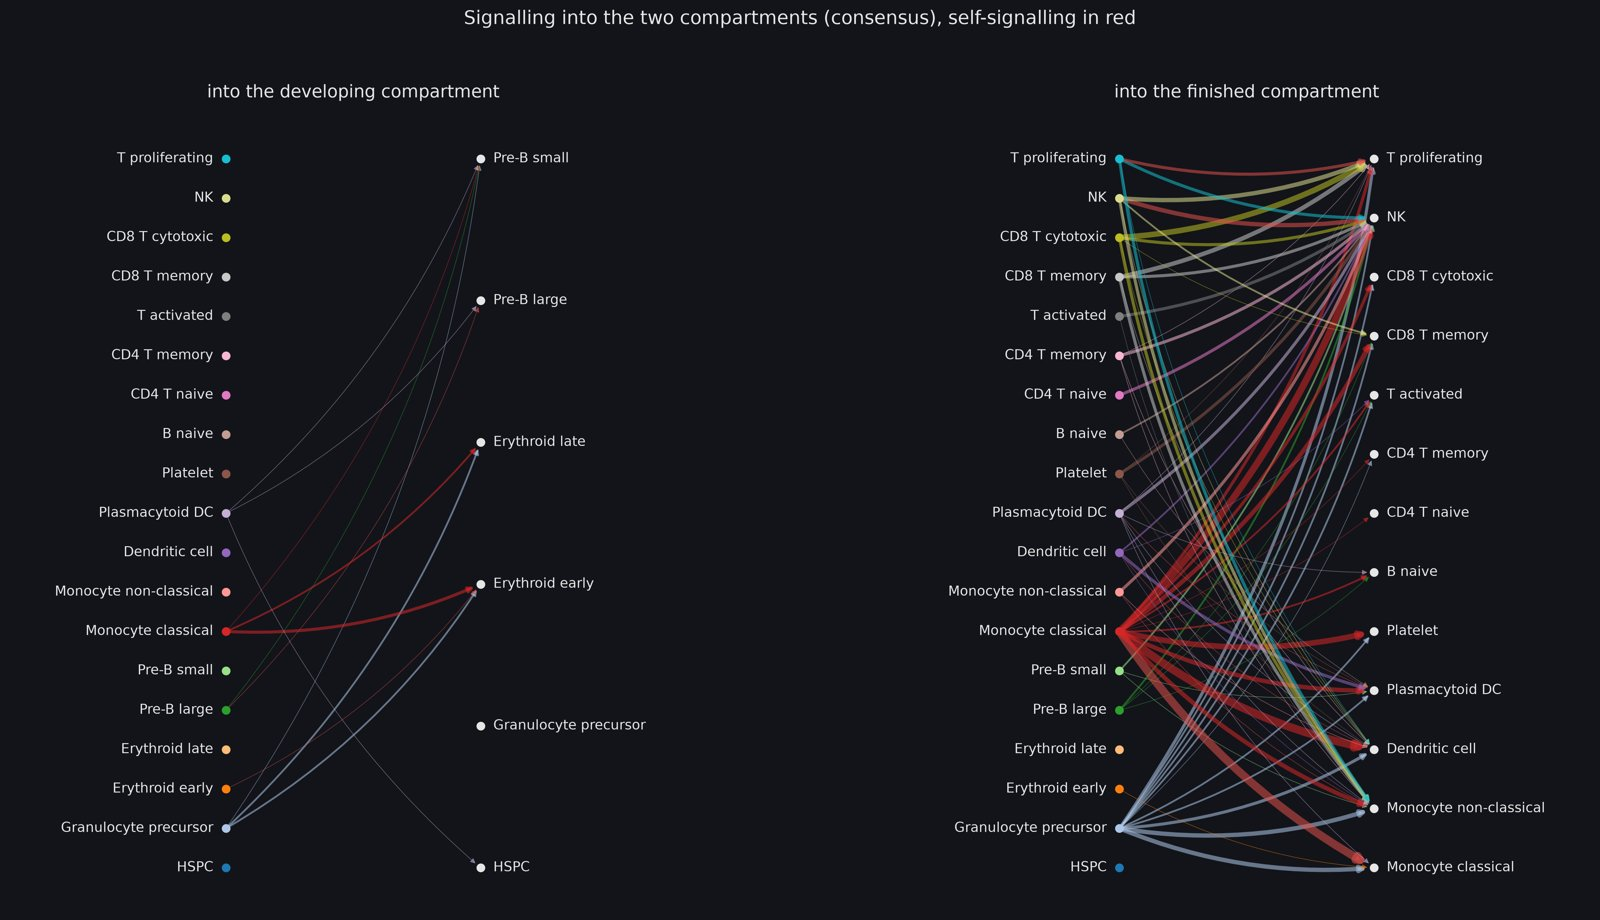

[Full-resolution figure](../figures/cell_cell_communication/cell_communication_report/cell_communication_report_hierarchy.png)

In [24]:
show("cell_cell_communication/cell_communication_report/cell_communication_report_hierarchy.png")

- **Signalling into each compartment**; senders left, receivers right;
  self-signalling in red.
- **The left panel is nearly empty (17 edges), the right one dense (178)** —
  the compartment result drawn.
- **Left panel**: only five senders have a line; Granulocyte precursor sits on
  the receiving side with nothing arriving; the thickest curves are Monocyte
  classical into the erythroid stages.
- **Right panel**: Monocyte classical and Granulocyte precursor fans cover most
  of the width; NK collects edges from almost every sender.

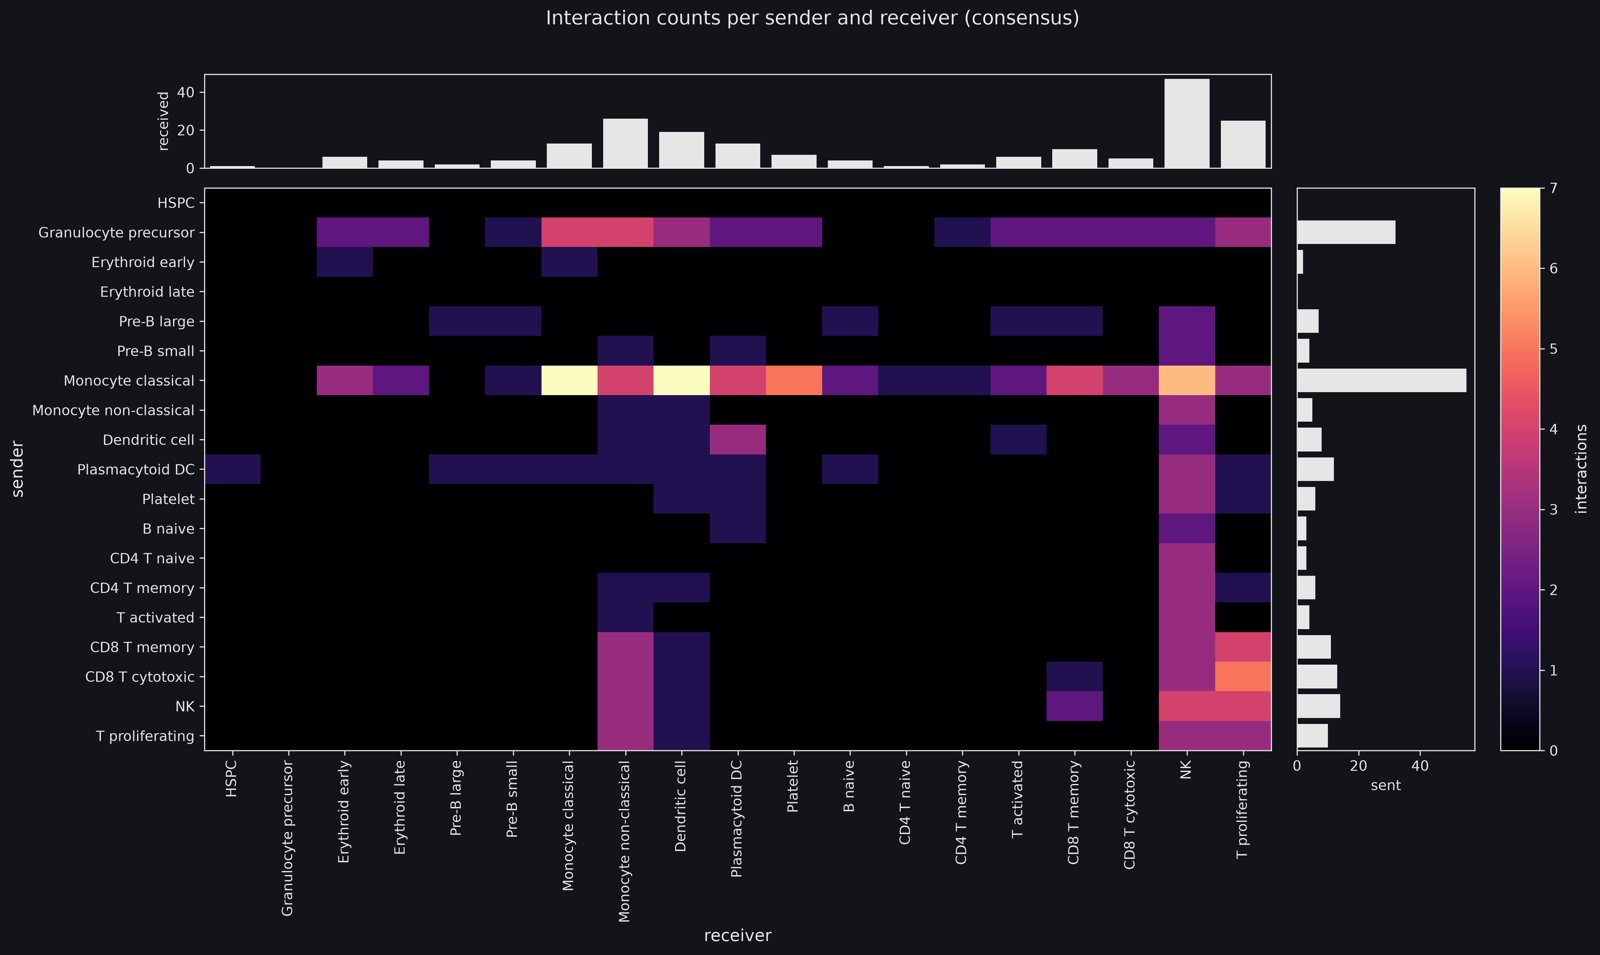

[Full-resolution figure](../figures/cell_cell_communication/cell_communication_report/cell_communication_report_heatmap.png)

In [25]:
show("cell_cell_communication/cell_communication_report/cell_communication_report_heatmap.png")

- **Sender × receiver counts with totals on the margins**, developing labels
  first.
- **The margins make the imbalance plain**: the Monocyte classical "sent" bar
  (55) is over 1.5 times any other; the NK "received" bar (47) is nearly twice
  any other.
- **Three blanks say the most**: the HSPC row and Erythroid late row (send
  nothing) and the Granulocyte precursor column (receives nothing).
- **Edges count database matches, not signal strength** — LIANA gives no
  communication probability.

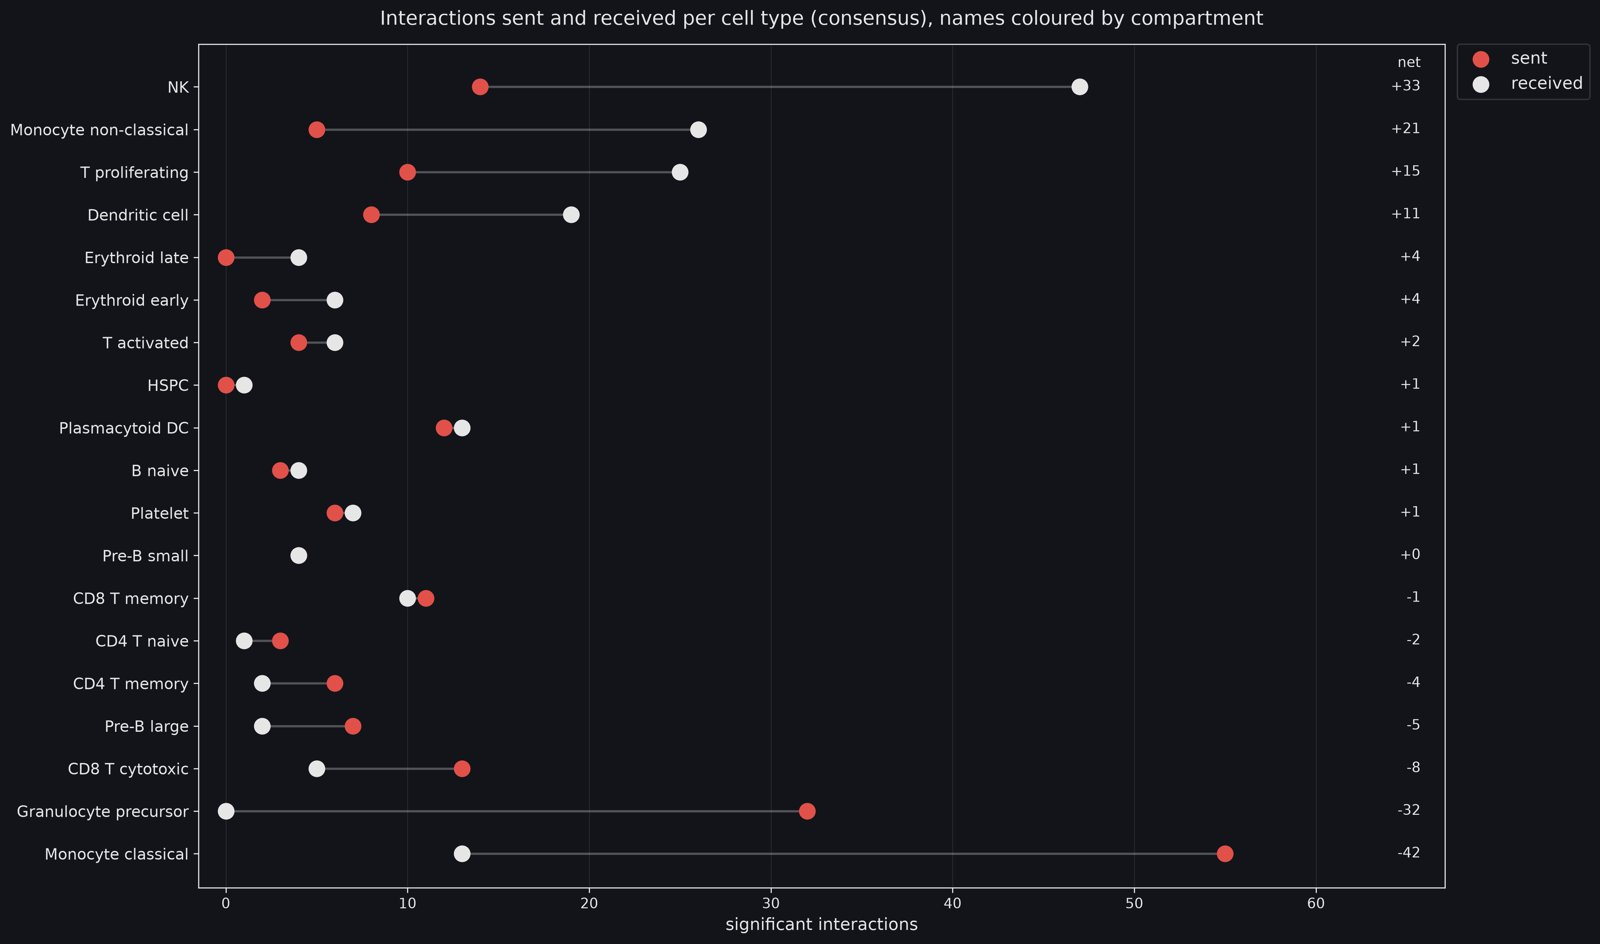

[Full-resolution figure](../figures/cell_cell_communication/cell_communication_report/cell_communication_report_sources_targets.png)

In [26]:
show("cell_cell_communication/cell_communication_report/cell_communication_report_sources_targets.png")

- **Sent (red) and received (white) per cell type**, ordered by net balance.
- **NK, Monocyte non-classical, T proliferating and Dendritic cell are net
  receivers; Monocyte classical and Granulocyte precursor are the big net
  senders.**
- **Developing labels are scattered through the order** (Erythroid late near
  the top, Granulocyte precursor near the bottom): being a sender or receiver
  has nothing to do with the compartment.

In [27]:
overlap_table = table("cell_cell_communication/cell_communication_report/cell_communication_report_resource_overlap.csv")
overlap_table.groupby(KEYS[2:])[["consensus", "cellphonedb"]].sum().query("cellphonedb > 0")

,,consensus,cellphonedb
ligand_complex,receptor_complex,,
APP,CD74,9,9
CLEC2D,KLRB1,0,1
PF4,CXCR3,2,2
RPS19,C5AR1,0,2
TNFSF13B,HLA-DPB1,4,6


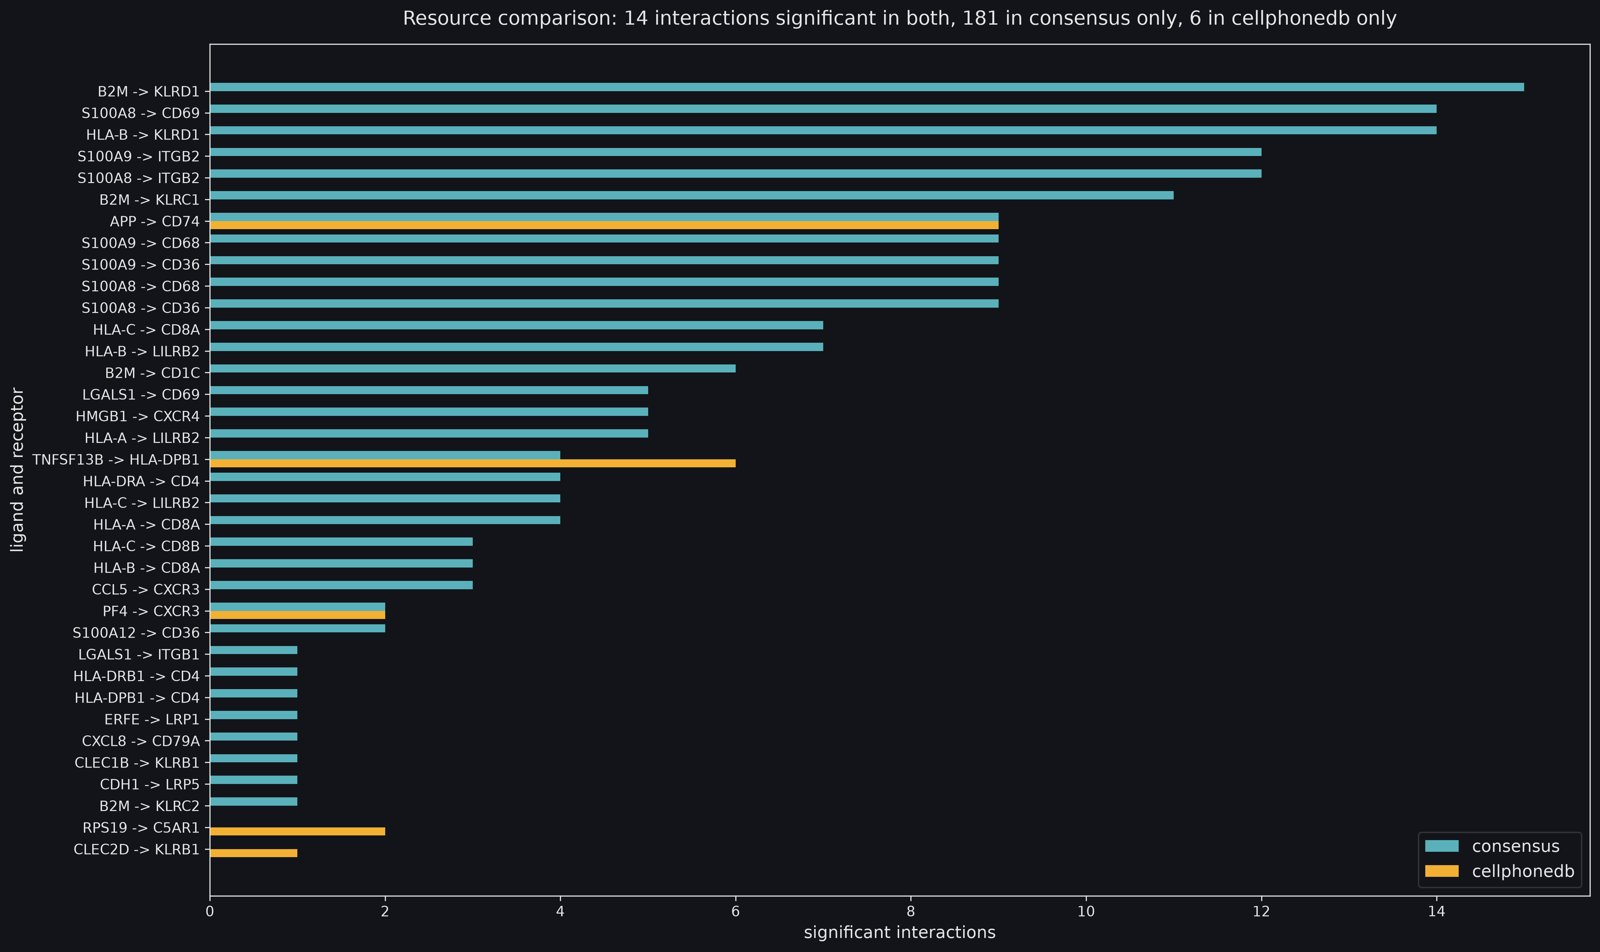

[Full-resolution figure](../figures/cell_cell_communication/cell_communication_report/cell_communication_report_resource_overlap.png)

In [28]:
show("cell_cell_communication/cell_communication_report/cell_communication_report_resource_overlap.png")

- **Significant interactions per ligand–receptor pair, by resource** (36
  pairs).
- **Almost all one colour**: consensus finds 181 interactions cellphonedb does
  not. Only 5 pairs have a cellphonedb bar, and only 3 have both.
- **`TNFSF13B → HLA-DPB1` is the one pair the small resource finds more of** (6
  against 4): the two extra rows go into B naive, just outside the consensus
  cut-off.

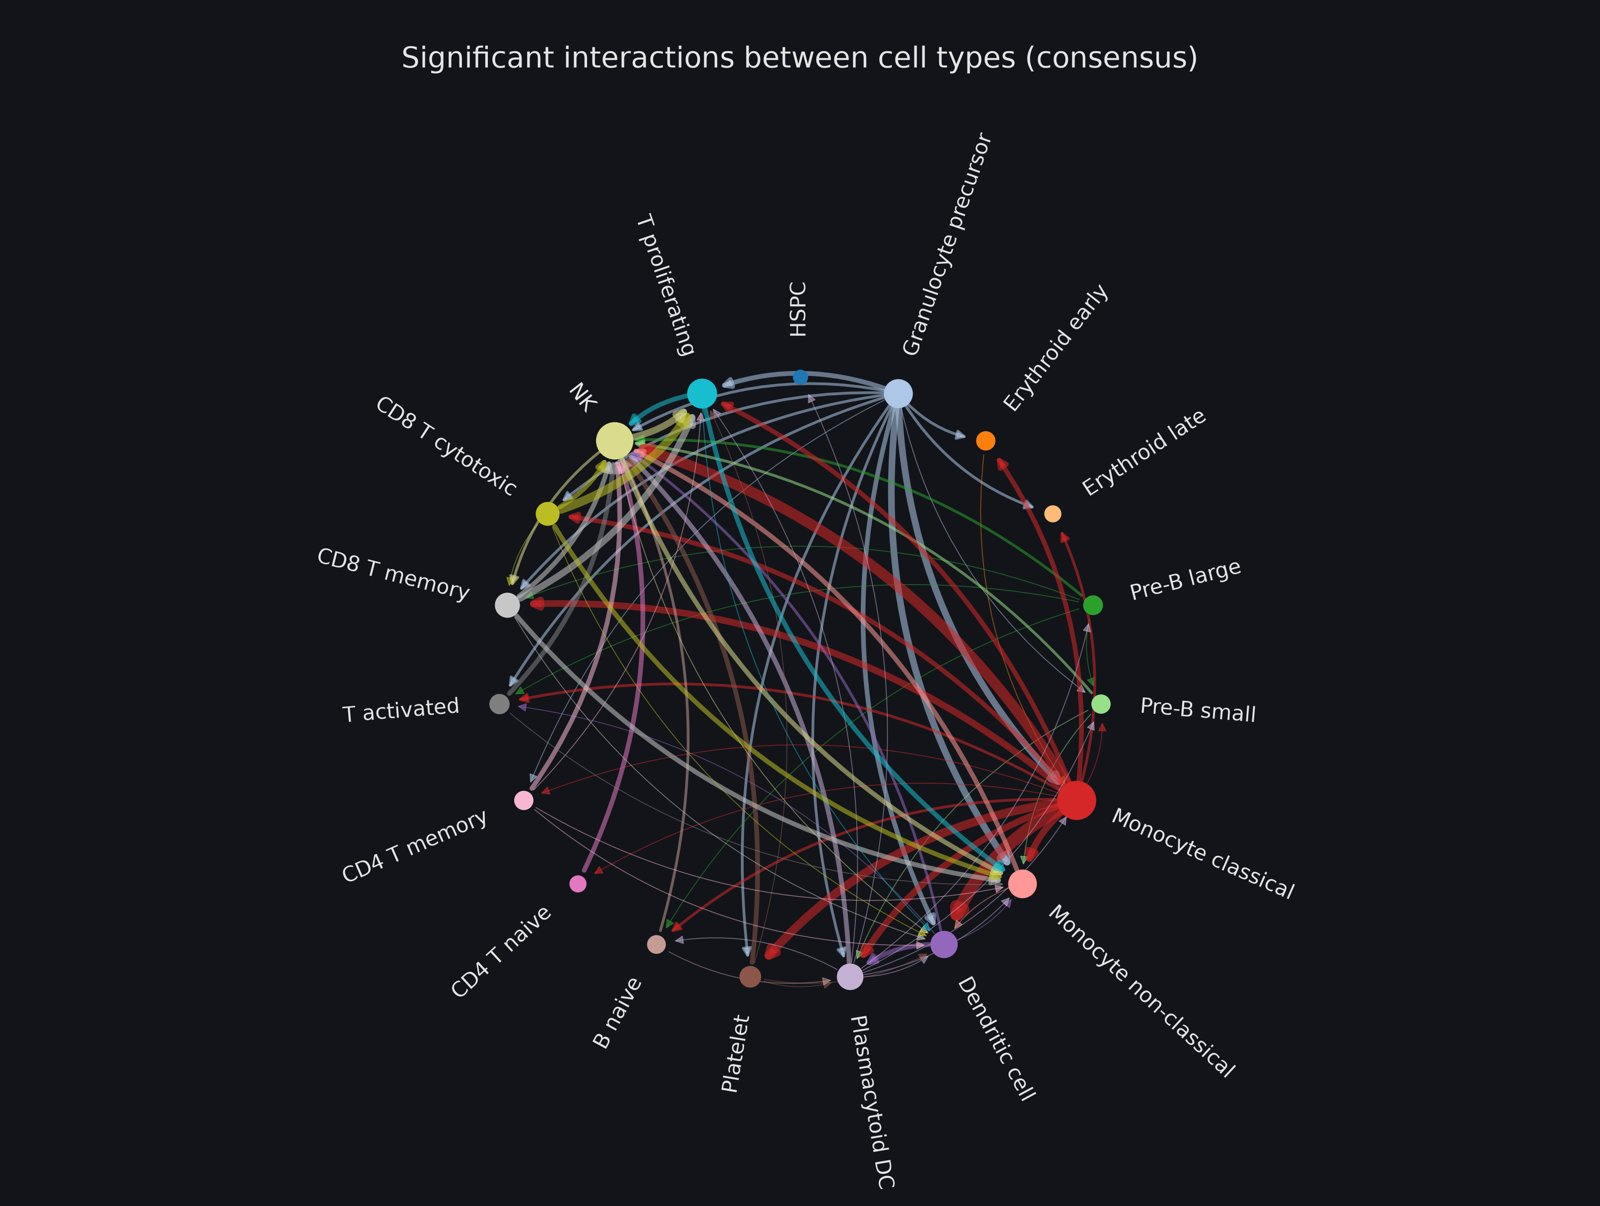

[Full-resolution figure](../figures/cell_cell_communication/cell_communication_report/cell_communication_report_circle.png)

In [29]:
show("cell_cell_communication/cell_communication_report/cell_communication_report_circle.png", width=750)

- **The same network on a circle**; node size = sent + received, edge width =
  count, edge colour = sender; self-signalling left out.
- **Two fans dominate**: the red Monocyte classical fan and the pale blue
  Granulocyte precursor fan. **NK is the largest node** and the meeting point
  for arrows from all round the circle. HSPC is the smallest node with one
  incoming edge.

## 7. Conclusions

**What holds**
- **14 interactions significant in both resources**: `APP → CD74` from
  plasmacytoid DC, `TNFSF13B → HLA-DPB1` (BAFF) into dendritic cells, and
  `PF4 → CXCR3` from platelets.
- **Platelet ligands are the most specific signals in the data** (`PF4 →
  CXCR3`, `CLEC1B → KLRB1`) — on 103 cells; `PF4 → CXCR3` into T proliferating
  cannot be checked per donor.
- **74 of 195 consensus interactions recur in all 8 donor lanes**, 117 in 6 or
  more.
- **Two real signalling programs**: the myeloid S100 alarmin set and the
  cytotoxic class I set; the cytotoxic group appears as senders and as
  receivers.
- **One new result**: S100A8/A9/A12 into CD36 on erythroid cells.

**What does not hold, and why**
- **80% of the consensus result is two ligand families** — class I (made by
  every cell, received by NK-only receptors) and S100 (the monocyte markers).
  True, but not new.
- **Sender/receiver totals measure annotated, loud ligands**, not signalling.
- **Rank aggregation lets near-unexpressed pairs through** (`CDH1 → LRP5`,
  `ERFE → LRP1`); `ERFE → LRP1` is refuted by the donor check.
- **The permutation p-value is 0 for 64% of everything** and is ignored.
- **"Seven methods" are two measurements**; the merged magnitude rank tracks
  its inputs only loosely.
- **T activated is 91% one donor** — likely a sample effect, not a cell type.
- **The pooled run misses 31 interactions every lane finds**, because one huge
  label (CD4 T naive) makes its relatives look unspecific.
- **Pathway names often misdescribe their content**, a third of terms are
  duplicates, and 17 of 45 are below chance.
- **The number of patterns is a choice**, not a result.
- **HSPC is invisible** to every catalogue-based method.

**Rules carried forward**
- Read expression level before rank; name the resource with every claim.
- Split by donor before trusting a label or an interaction; count whether a
  lane could test it before reading a zero.
- Open the gene pairs behind any pathway name; read fold and count together.
- Keep the pre-scaling fit next to any normalised usage.

## Figures not shown

All in `figures/cell_cell_communication/`:

- `lr_rank/`: [heatmap, cellphonedb](../figures/cell_cell_communication/lr_rank/lr_rank_heatmap_cellphonedb.png),
  [dotplot, cellphonedb](../figures/cell_cell_communication/lr_rank/lr_rank_dotplot_cellphonedb.png)
- `lr_methods/`: [agreement, cellphonedb](../figures/cell_cell_communication/lr_methods/lr_methods_agreement_cellphonedb.png)
- `lr_donors/`: [reproducibility, cellphonedb](../figures/cell_cell_communication/lr_donors/lr_donors_reproducibility_cellphonedb.png)
- `cell_communication_report/`: [chord](../figures/cell_cell_communication/cell_communication_report/cell_communication_report_chord.png),
  [top 30 dotplot](../figures/cell_cell_communication/cell_communication_report/cell_communication_report_dotplot.png)